# Sequential Quadratic Programming

**Reading:** Biegler (2010), *Nonlinear Programming*, §6.2, pp. 135–151; Nocedal & Wright (2006), *Numerical Optimization*, Chapter 18, pp. 529–562.

This guide supplements Lecture 23 with complete QP certificates, elastic repairs, line-search and trust-region algorithms, reduced-space details and local-rate conditions. The implementation laboratory then exposes each dense QP/KKT solve and preserves successful runs and useful failure cases.

Start with the [QP model](#sqp-iqp-model), [elastic repairs](#sqp-elastic-models), [trust-region families](#sqp-trust-models), or [local rates](#sqp-local-rates). [Constrained Globalization](Constrained-Globalization.ipynb) supplies the general acceptance proofs and Maratos correction. [Equality Newton](Interior-Point1.ipynb) supplies the equality-QP bridge; [Quasi-Newton Methods](../6/Quasi-Newton-Methods.ipynb) supplies the general BFGS derivation.

The prototype implements scalar-relaxed **line-search** SQP. The trust-region, SLQP and sparse methods are fully described here but require different computational machinery; they are not implemented by the prototype.

```{warning}
**AI-drafted prose, not yet reviewed by Prof. Dowling.**

Some of the writing on this page was drafted or edited by an AI assistant and has not yet been reviewed: 39 added markdown cells, measured against the last version of this notebook predating AI editing (2026-08-17).

This notice is about the *prose only*. It says nothing either way about the code, the numbers or the figures, which are checked separately. It is removed once the page has been reviewed.
```

(sqp-iqp-model)=

## Formulating the inequality QP

Use the course convention $L=f+\mathbf v^{\mathsf T}\mathbf h+\mathbf u^{\mathsf T}\mathbf g$, with equalities $\mathbf h=\mathbf0$, inequalities $\mathbf g\le\mathbf0$, and $\mathbf u\ge\mathbf0$. At iteration $k$, put $\mathbf a_k=\nabla f(\mathbf x^k)$ and $\mathbf B_k=\nabla_{\mathbf{xx}}^2L(\mathbf x^k,\mathbf v^k,\mathbf u^k)$ or a chosen approximation. An IQP subproblem is

$$\min_{\mathbf d}\ \mathbf a_k^{\mathsf T}\mathbf d+\tfrac12\mathbf d^{\mathsf T}\mathbf B_k\mathbf d\quad\text{s.t.}\quad
\mathbf h_k+\mathbf J_h^k\mathbf d=\mathbf0,\qquad
\mathbf g_k+\mathbf J_g^k\mathbf d\le\mathbf0.$$

This uses a quadratic Lagrangian model and affine constraint models. Linearizing a nonlinear inequality does not certify feasibility of the nonlinear trial. The QP supplies a step and multiplier estimates; an acceptance procedure from [Constrained Globalization](Constrained-Globalization.ipynb) selects the new point. [Equality Newton](Interior-Point1.ipynb) owns the exact equality KKT/QP bridge and its local assumptions.

In the bound formulation used by the code, inequalities have already been represented by slack variables and simple bounds. The subproblem is

$$\min_{\mathbf d}\ \mathbf a_k^{\mathsf T}\mathbf d+\tfrac12\mathbf d^{\mathsf T}\mathbf B_k\mathbf d\quad\text{s.t.}\quad
\mathbf h_k+\mathbf J_k\mathbf d=\mathbf0,\qquad
\mathbf x_L\le\mathbf x^k+\mathbf d\le\mathbf x_U.$$

Here the code's argument `g` means the **objective gradient**, its `J` is a row Jacobian, and its `lam` means the course equality multiplier $\mathbf v$. Its bound-QP solver returns a signed gradient `zeta`: positive at a lower bound, negative at an upper bound. At a solved QP, $\boldsymbol\zeta=\mathbf u_L-\mathbf u_U$ and stationarity is $\mathbf a+\mathbf B\mathbf d+\mathbf J^{\mathsf T}\bar{\mathbf v}-\mathbf u_L+\mathbf u_U=\mathbf0$. Do not read this signed quantity as a nonnegative inequality multiplier.

Biegler §6.2, pp.135–136; Nocedal–Wright (18.11), p.533.

(sqp-signs)=

## Function signs and multiplier signs

Nocedal–Wright writes $L_{NW}=f-\boldsymbol\lambda_E^{\mathsf T}\mathbf h-\boldsymbol\lambda_I^{\mathsf T}\mathbf c_I$ with $\mathbf c_I\ge\mathbf0$. For the same equality function, $\mathbf v=-\boldsymbol\lambda_E$. When $\mathbf g=-\mathbf c_I$, however, $\mathbf u=\boldsymbol\lambda_I$. Thus equality multipliers reverse sign but inequality multipliers **do not** under this function conversion. For a lower bound, $c_L=x-x_L$ and $g_L=x_L-x$; for an upper bound, $c_U=x_U-x$ and $g_U=x-x_U$. Both nonnegative bound multipliers retain their values. State the constraint function and Lagrangian together when translating.

If a bound set were known, matrices $\mathbf E_L,\mathbf E_U$ collect the corresponding unit **columns**. The QP would impose $\mathbf E_L^{\mathsf T}(\mathbf x^k+\mathbf d)=\mathbf E_L^{\mathsf T}\mathbf x_L$ and its upper-bound analogue. The general inequality QP keeps the bounds as inequalities and chooses which are active at its solution. Active bounds at the current point and at the QP endpoint need not be the same.

(sqp-zero-step)=

## A correctly scoped zero-step certificate

![Flat QP minimizers span more than the selected endpoint face.](https://raw.githubusercontent.com/ndcbe/optimization/b673397597db982db71beabe2a105bfde0267ff4/media/figures/sqp-flat-face.png)

Flat QP minimizers span more than the selected endpoint face.

If a QP KKT solution has $\mathbf d=\mathbf0$, its affine residuals equal the original constraint values. QP stationarity becomes NLP stationarity, and dual feasibility/complementarity apply at the same point. Therefore **a zero QP KKT step gives an NLP KKT point**, without needing a separate uniqueness argument. It does not alone prove second-order optimality or a global minimum. In computation, verify the QP's KKT residuals and solve status rather than assuming its returned step is exact.

A useful converse holds with sufficient strict convexity on the equality tangent. Suppose the current point is NLP KKT and $\mathbf B$ is positive definite on $\ker\mathbf J_h$. Zero is a feasible QP step. For any other feasible $\mathbf d$, stationarity gives

$$\mathbf a^{\mathsf T}\mathbf d=-\mathbf v^{\mathsf T}\mathbf J_h\mathbf d-\mathbf u^{\mathsf T}\mathbf J_g\mathbf d\ge0.$$

The equality term is zero. Positive multipliers only occur at active inequalities; there $\mathbf J_{g,i}\mathbf d\le0$, so each remaining term is nonnegative. Since $\mathbf J_h\mathbf d=0$ and $\mathbf d\ne0$, $\frac12\mathbf d^{\mathsf T}\mathbf B\mathbf d>0$. Hence the QP objective at every nonzero feasible step exceeds its value at zero, making zero the unique global QP minimum. Full positive definiteness is a convenient sufficient special case. This converse imposes more than curvature on one selected all-active face.

The distinction matters in Biegler Theorem 6.1, p.136. Consider $f=x_2^2$, no equalities, $0\le x_1\le1$, current $(0,0)$, and QP Hessian $\operatorname{diag}(0,2)$. The QP may return $(1,0)$ with zero upper-bound multiplier. At that endpoint the active row $[1,0]$ is independent, the null curvature is2, and its KKT matrix is nonsingular. Yet all $(d_1,0)$ with $0\le d_1\le1$ minimize the QP. The original current point is NLP KKT with the **same zero multipliers**, despite the selected nonzero step. Positivity on the all-active null space misses the weak bound's critical directions. In the book's fixed-face proof, zero does not satisfy that endpoint's upper-bound equality. Use the certificate/converse above rather than promoting active-face nonsingularity to global primal uniqueness. [Second Order Conditions](Second-Order.ipynb) supplies the critical-cone distinction.

A sharper fixed-face converse can instead assume strict complementarity at the **selected QP endpoint**, the same multipliers satisfying NLP KKT at the current point, and positive curvature on that selected active null space. Every positively weighted bound/inequality is active at both points, so its affine row gives $\mathbf J_A\mathbf d=\mathbf0$. Subtracting the two stationarity equations gives $\mathbf B\mathbf d=\mathbf0$. Therefore $\mathbf d^{\mathsf T}\mathbf B\mathbf d=0$ and active-null positivity forces $\mathbf d=\mathbf0$. The flat example fails this added strict-complementarity assumption. This is a different sufficient converse, not a reason to omit weakly active directions from the general theorem.

(sqp-active-identification)=

## Active-set identification and well-posedness

![Strictly and weakly weighted bounds respond differently to center perturbations.](https://raw.githubusercontent.com/ndcbe/optimization/b673397597db982db71beabe2a105bfde0267ff4/media/figures/sqp-active-identification.png)

Strictly and weakly weighted bounds respond differently to center perturbations.

Nocedal–Wright Theorem 18.1, p.533, assumes a local KKT solution, LICQ, strict complementarity and SOSC. Near the solution and its relevant multiplier vector, a **local QP solution branch** has the same active set. Biegler Theorem 6.5, pp.141–142, gives the analogous eventual-set property for a converging SQP sequence. This stabilizes the active-set algebra; it does not prove global QP uniqueness far away or remove the need for accepted full steps and local smoothness/Hessian assumptions.

Strict complementarity is sufficient for this identification theorem, not necessary for every example to identify its set. For $\min x^2$ subject to $x\ge0$, the solution has zero multiplier, but the exact QP step from a positive start reaches zero immediately and its active set remains identifiable. Without strict complementarity, the theorem no longer excludes changing weakly active sets; it does not assert that all such problems fail.

Likewise, LICQ is a sufficient KKT factorization condition, not a necessary condition for unique primal optimization: $\min x^2$ with duplicate inequalities $-x\le0,-2x\le0$ has a unique minimum. A solver may select an independent working subset. It must still distinguish truly redundant rows from dependent gradients with inconsistent residuals: the equations $d=0$ and $d=-1$ have the same gradient but cannot both be satisfied. Discarding the latter merely because its gradient is dependent changes the problem. Preserve primal/dual residual checks when rank safeguards or least-squares solves are used.

Three separate questions govern the subproblem: is its feasible set nonempty, is its objective bounded below/attained, and which primal/dual solution is unique? Full indefiniteness need not make an equality QP unbounded when reduced curvature is positive. A compact inequality feasible set bounds a continuous quadratic objective even if it is indefinite. Independent active rows with positive curvature on that face make its KKT system nonsingular; they need not settle global minimization across other faces. These are distinct issues.

(sqp-iqp-eqp-slqp)=

## IQP, EQP and SLQP

An **IQP** outer method solves an inequality QP and reads a working-set estimate from its solution. An **EQP** outer method estimates a working set first, then computes an equality-QP step on that set. An active-set QP *subsolver* can be used inside IQP; choosing it does not convert the outer algorithm to EQP. Nocedal–Wright §18.2, pp.533–534.

**Warm starts** reuse a previous QP working set or factorization when successive subproblems are related. They can reduce work near a stable solution; they do not guarantee that the next set is identical. Whether IQP or EQP is cheaper depends on derivative evaluation cost, sparsity, conditioning, degeneracy and the quality of the set estimate. Neither family requires exhaustive enumeration of every inequality subset.

**SLQP** uses an LP phase to estimate a working set, followed by an EQP phase. A hard-constraint LP can itself be infeasible, so the practical scheme uses a penalty LP on an infinity-norm trust box. Its objective is the linear objective model plus the piecewise-linear constraint violation. A basic optimal solution can identify a working set, but not every LP optimum returned by every solver is a vertex. Select independent active rows and retain feasibility/restoration safeguards.

The fuller Nocedal–Wright construction, pp.551–552, uses a Cauchy point $\mathbf p^C=\alpha_{LP}\mathbf p^{LP}$ giving sufficient decrease in the merit **model**. It selects an independent subset of constraints active in the LP model. In the EQP objective, violated constraints contribute the derivative of their current penalty branch: equality residuals contribute $\rho_{\rm pen}\operatorname{sign}(h_i^{lin})\nabla h_i$, and violated course inequalities $g_i^{lin}>0$ contribute $\rho_{\rm pen}\nabla g_i$. Working-set rows are enforced at equality inside a **Euclidean** trust ball with its own radius. Let $\mathbf p^Q$ be that candidate. The total step is

$$\mathbf p=\mathbf p^C+\alpha_Q(\mathbf p^Q-\mathbf p^C),\qquad0\le\alpha_Q\le1,$$

chosen to improve the merit model. This is not simply discarding the LP point and taking an unconstrained equality-QP solution. LP and EQP radii serve different roles. The penalty update below also applies, with a zero-Hessian LP model.

(sqp-inconsistent-model)=

## Inconsistent linearizations: complete worked example

![A feasible nonlinear point can coexist with contradictory affine step requirements.](https://raw.githubusercontent.com/ndcbe/optimization/b673397597db982db71beabe2a105bfde0267ff4/media/figures/sqp-affine-inconsistency.png)

A feasible nonlinear point can coexist with contradictory affine step requirements.

The constraints $x\le1,x^2\ge4$ are feasible at $x=-2$, but at $x=1$ their linearizations require $d\le0$ and $d\ge3/2$. A feasible NLP can have an empty local affine model inside its physical bounds.

Biegler Example 6.3, p.140, uses

$$\min x_1+x_2,\quad h_1=1+x_1-x_2^2+x_3=0,\quad h_2=1-x_1-x_2^2+x_4=0,$$

with $0\le x_2\le2$ and $x_3,x_4\ge0$. At $(0,.1,0,0)$ both residuals are $.99$, not the printed first value $1.01$. The affine rows are

$$.99+d_1-.2d_2+d_3=0,\qquad .99-d_1-.2d_2+d_4=0,$$

with $-.1\le d_2\le1.9$ and $d_3,d_4\ge0$. Adding the rows gives $.4d_2=1.98+d_3+d_4\ge1.98$, hence $d_2\ge4.95$, contradicting its upper bound. The held errata restores the omitted starting-point components but does not repair the $1.01$ arithmetic.

The global solution is $(-3,2,6,0)$, with objective $-1$. A complete verification eliminates the equalities: nonnegative slacks imply $1-x_2^2\le x_1\le x_2^2-1$, so $1\le x_2\le2$. At a fixed $x_2$, minimize by $x_1=1-x_2^2$, giving $f=1-x_2^2+x_2$. Its derivative $1-2x_2<0$ on $[1,2]$, so the unique minimizing $x_2$ is2 and the remaining variables follow. Course equality multipliers $(0,1)$, upper $x_2$ multiplier3 and lower $x_4$ multiplier1 satisfy KKT. This global calculation uses this example's special structure; a generic SQP status is not a global certificate.

(sqp-elastic-models)=

## Two elastic repairs and what relaxation means

![Residual slacks and their multiplier cap.](https://raw.githubusercontent.com/ndcbe/optimization/b673397597db982db71beabe2a105bfde0267ff4/media/figures/sqp-elastic-cap.png)

Residual slacks and their multiplier cap.

The $\ell_1$ elastic QP introduces $\mathbf s,\mathbf t\ge\mathbf0$:

$$\min_{\mathbf d,\mathbf s,\mathbf t}\ \mathbf a^{\mathsf T}\mathbf d+\tfrac12\mathbf d^{\mathsf T}\mathbf B\mathbf d+\rho_{\rm pen}\mathbf1^{\mathsf T}(\mathbf s+\mathbf t),\quad
\mathbf h+\mathbf J\mathbf d=\mathbf s-\mathbf t,\quad\mathbf x_L\le\mathbf x+\mathbf d\le\mathbf x_U.$$

For a bound-feasible current point, zero step and component positive/negative parts of $\mathbf h$ give a feasible lifted point. More generally, a nonempty physical box allows a bound-feasible step and appropriate residual slacks. Strict positive primal curvature gives a finite unique primal minimum; mere feasibility with an indefinite unbounded objective does not. At optimality with positive weight, the slacks represent the residual's actual positive and negative parts. Their stationarity implies $-\rho_{\rm pen}\le\bar v_j\le\rho_{\rm pen}$; a positive $s_j$ forces $\bar v_j=\rho_{\rm pen}$ and a positive $t_j$ forces $\bar v_j=-\rho_{\rm pen}$. This multiplier cap belongs to the l1 formulation, not the scalar formulation. Biegler6.13p138; Nocedal–Wright18.12p536.

The **scalar** repair implemented below minimizes

$$\mathbf a^{\mathsf T}\mathbf d+\tfrac12\mathbf d^{\mathsf T}\mathbf B\mathbf d+M(\xi+\xi^2/2),\quad
(1-\xi)\mathbf h+\mathbf J\mathbf d=\mathbf0,$$

with the physical step bounds and **$0\le\xi\le1$**. The book's6.16only prints $\xi\ge0$; the notebook adds the upper bound. A zero step with $\xi=1$ is feasible when the current point satisfies the box. For $\mathbf B\succ0,M>0$, the lifted objective Hessian $\operatorname{diag}(\mathbf B,M)$ is positive definite, giving a unique minimizer on the convex feasible set. The $\xi^2$ term alone does not make flat primal directions unique.

At $\xi=0$ the chosen step satisfies the original affine equalities. For $0<\xi<1$ it contracts their residual by $1-\xi$. A positive $\xi$ does **not** prove that exact affine feasibility was impossible: for $h=-1,J=1,a=0,B=1000,M=1$, and physical $x\in[0,2]$ at $x=0$, the exact step1is feasible but the weighted optimum chooses $\xi=999/1001$ and $d=2/1001$. A finite weight can prefer partial relaxation. With only the book's lower bound on $\xi$, the data $a=100,B=M=1,h=-1,J=1$ and broad physical bounds produce $\xi=50,d=-49$. Thus a contraction interpretation needs an explicit domain/safeguard.

At $\xi=1$ the step is tangent to the affine equalities; it need not be zero. For $h=x_1-x_1^2+1$, current $(0,0)$, lower bound $x_1\ge0$, $\mathbf a=(0,-1)$ and $\mathbf B=\mathbf I$, the guarded scalar QP forces $\xi=1,d_1=0$ but selects $d_2=1$. A feasible nonlinear point exists at $x_1=(1+\sqrt5)/2$. Diagnose lost contraction/restoration needs; do not infer global infeasibility or zero tangent movement.

For Example 6.3, the relaxed row sum gives $1.98(1-\xi)\le.76$, so the minimum **feasible** relaxation is $1-.76/1.98=.616161\ldots$. The actual solver below computes its selected relaxation separately. At the all-zero start, $\xi=1$ is forced by the two rows and nonnegative slacks, but there remain feasible $d_2$ values in $[0,2]$. For this example's gradient and positive Hessian, the minimizing primal step is zero. Preserve that specific failure; do not turn it into a universal statement about $\xi=1$.

(sqp-elastic-descent)=

## Elastic merit descent: complete sign argument

![The elastic merit-descent argument uses the actual contraction and bound signs.](https://raw.githubusercontent.com/ndcbe/optimization/b673397597db982db71beabe2a105bfde0267ff4/media/figures/sqp-descent-proof.png)

The elastic merit-descent argument uses the actual contraction and bound signs.

For the actual scalar step, $\mathbf J\mathbf d=-(1-\xi)\mathbf h$. The forward norm expansion from [Constrained Globalization](Constrained-Globalization.ipynb) gives

$$D\phi_p=\mathbf a^{\mathsf T}\mathbf d-\rho_{\rm pen}(1-\xi)\|\mathbf h\|_p.$$

At the QP endpoint, bound complementarity and a bound-feasible current point imply $\bar{\mathbf u}_L^{\mathsf T}\mathbf d\le0$ and $\bar{\mathbf u}_U^{\mathsf T}\mathbf d\ge0$. Dot QP stationarity with $\mathbf d$ and substitute its equality row:

$$\mathbf a^{\mathsf T}\mathbf d=-\mathbf d^{\mathsf T}\mathbf B\mathbf d+(1-\xi)\bar{\mathbf v}^{\mathsf T}\mathbf h+\bar{\mathbf u}_L^{\mathsf T}\mathbf d-\bar{\mathbf u}_U^{\mathsf T}\mathbf d.$$

For $0\le\xi<1$, dual exponents $1/p+1/q=1$ and $\rho_{\rm pen}\ge\|\bar{\mathbf v}\|_q+\epsilon_{\rm pen}$ give

$$D\phi_p\le-\mathbf d^{\mathsf T}\mathbf B\mathbf d-\epsilon_{\rm pen}(1-\xi)\|\mathbf h\|_p.$$

With $\mathbf B\succ0$, a nonzero step is strictly descending; at zero residual/zero step it is stationary, not a strict-descent exception. Biegler6.21p140prints a positive quadratic sign followed by a strict-negative claim; the preceding stationarity calculation requires the negative sign above. Full positive curvature is used here. The weaker reduced-curvature variants require the appropriate coupling-aware analysis from L22, not this unchanged multiplier rule.

(sqp-line-search)=

## A safeguarded line-search algorithm

A complete scalar-relaxed line-search outline is:

1. Start inside a consistent physical box. Evaluate $f,\mathbf a,\mathbf h,\mathbf J$ and the chosen curvature model.
2. Solve the guarded scalar QP, checking its primal/dual residuals and inner solve status. If it produces no adequate contraction or progress, diagnose restoration or a stall rather than declaring the entire NLP infeasible.
3. Compute the actual forward merit derivative. For the full-positive model and $\xi<1$, use the multiplier bound above; alternatively use a properly safeguarded direct slope rule. Compare all trials with the same current weight.
4. Backtrack from a full step with $0<\eta<1/2$ until $\phi_p(\mathbf x+\alpha\mathbf d)\le\phi_p(\mathbf x)+\eta\alpha D\phi_p$. Use L22's correction safeguard near the solution. If a correction fails, discard it; if the line search exhausts its limit, report failure/restoration rather than unconditionally accepting its last trial.
5. Update the primal and specified dual estimates. Re-evaluate **actual new-point** feasibility, stationarity, dual signs and complementarity; a small step alone is not convergence. Then form the fixed-multiplier secant pair when updating curvature.

Biegler Algorithm 6.1p141takes full QP multiplier updates independently of primal $\alpha$. Nocedal–Wright Algorithm 18.3p545damps both: $\boldsymbol\lambda^{k+1}=\boldsymbol\lambda^k+\alpha(\hat{\boldsymbol\lambda}-\boldsymbol\lambda^k)$. They are different algorithm choices. Neither implies intermediate complementarity automatically.

Nocedal–Wright's model-based rule uses $V(\mathbf d)=\|\mathbf h+\mathbf J\mathbf d\|_1$ and $q_\rho=f+\mathbf a^{\mathsf T}\mathbf d+(\sigma/2)\mathbf d^{\mathsf T}\mathbf B\mathbf d+\rho V(\mathbf d)$. Require $q_\rho(\mathbf0)-q_\rho(\mathbf d)\ge\kappa\rho[V(\mathbf0)-V(\mathbf d)]$, $0<\kappa<1$. If the violation decrease $\Delta V>0$, this gives

$$\rho\ge\frac{\mathbf a^{\mathsf T}\mathbf d+(\sigma/2)\mathbf d^{\mathsf T}\mathbf B\mathbf d}{(1-\kappa)\Delta V}.$$

For an exact affine-feasibility step $\Delta V=\|\mathbf h\|_1$, this is18.36p542. For a relaxed step use its actual $\Delta V$; do not divide by zero at an already feasible tangent step. Algorithm 18.3uses $\sigma=1$. This rule measures predicted progress without relying directly on the multipliers; its behavior depends on the problem and model, not an unconditional superiority claim.

The existing code adds its own hybrid weight safeguard when relaxation is large. It is not literally either textbook algorithm in every branch. Its original stopping/failure behavior remains below, with separate diagnostic interpretation.

(sqp-global-convergence)=

## What the global argument must establish

![Uniform decrease, summability and limit transfer are separate proof steps.](https://raw.githubusercontent.com/ndcbe/optimization/b673397597db982db71beabe2a105bfde0267ff4/media/figures/sqp-convergence-proof.png)

Uniform decrease, summability and limit transfer are separate proof steps.

The term **global convergence** refers to approach to first-order stationary/KKT points from a larger class of starts, under algorithmic assumptions. It does not mean the globally best solution of a nonconvex NLP.

A transparent sufficient argument assumes compact primal/trial iterates, bounded QP multipliers, an eventually fixed weight, a merit lower bound, accepted step lengths $\alpha_k\ge\underline\alpha>0$, $\mathbf B_k\succeq b\mathbf I$ with $b>0$ and uniformly bounded norm, and contraction $\xi_k\le1-\gamma$ with $\gamma>0$. The derivative bound above and Armijo yield

$$\phi_k-\phi_{k+1}\ge\eta\underline\alpha\big[b\|\mathbf d_k\|_2^2+\epsilon_{\rm pen}\gamma\|\mathbf h_k\|_p\big].$$

Summing against the merit lower bound gives finite sums of squared steps and violations, hence $\mathbf d_k\to\mathbf0$ and $\mathbf h_k\to\mathbf0$. Bounded curvature makes the QP stationarity defect $-\mathbf B_k\mathbf d_k$ vanish. Compactness and bounded duals allow subsequences with convergent primal/dual values; continuity gives stationarity and dual signs. QP complementarity at $\mathbf x^k+\mathbf d_k$ transfers to $\mathbf x^k$ because the difference in each product is a bounded multiplier times a vanishing step. Thus the limit is NLP KKT. This proof does not establish one convergent whole sequence, SOSC or a global minimum.

Biegler Theorem 6.4p141states a related KKT limit-point result for compact primal/trial sequences, uniform continuity, positive bounded curvature, LICQ, solvable QPs with $\xi<1$ and a sufficiently large weight. Its precedingp140discussion separately emphasizes contraction bounded away from1. Pointwise $\xi<1$ or pointwise positivity is not a uniform constant; an implementation must establish the safeguards its proof uses. Nocedal–Wright18.3p557explicitlyincludes bounded steps/dual values, a fixed sufficiently large penalty and its particular model-decrease line search. The prototype's status string does not verify those global hypotheses. The finite-update issue for a bounded monotone weight is explained fully at the L22 reference.

(sqp-constrained-damping)=

## Fixed-multiplier curvature and damping

Use $\mathbf s_k=\mathbf x^{k+1}-\mathbf x^k$ and

$$\mathbf y_k=\nabla_{\mathbf x}L(\mathbf x^{k+1},\mathbf v^{k+1},\mathbf u^{k+1})-\nabla_{\mathbf x}L(\mathbf x^k,\mathbf v^{k+1},\mathbf u^{k+1}).$$

Both gradients fix the same updated multipliers. For linear physical bounds, the bound-gradient contributions cancel; the code therefore uses objective and equality-gradient terms. Changing the multiplier in the second term instead introduces an unwanted dual-step contribution. The general BFGS and damping derivations remain at [Quasi-Newton Methods](../6/Quasi-Newton-Methods.ipynb); this section applies them to constrained curvature.

For $\mathbf B\succ0,\mathbf s\ne\mathbf0$, put $a=\mathbf s^{\mathsf T}\mathbf B\mathbf s>0$ and $b=\mathbf s^{\mathsf T}\mathbf y$. Powell's rule takes $\theta=1$ if $b\ge.2a$, otherwise $\theta=.8a/(a-b)$, and $\mathbf r=\theta\mathbf y+(1-\theta)\mathbf B\mathbf s$. The actual rule chooses $0<\theta\le1$; zero is a limiting conceptual case, not a finite selected value. If it selects1, the positive-curvature test has passed, so that actual ordinary update preserves definiteness. Forcing1while ignoring the test can produce an indefinite update. The convex combination is in **secant vectors**; updated matrices are not generally their affine mixture.

A constrained family makes negative measured curvature concrete. Let $f=-2x_1^2+\frac12(x_2-2)^2$, $h=x_1$, with solution $(0,2)$. Its true full Hessian is $\operatorname{diag}(-4,1)$ but its tangent curvature is1. At $(-\epsilon,2-3\epsilon)$ with $\mathbf B=\operatorname{diag}(2,3)$, the equality-QP step is $(\epsilon,\epsilon)$ and the fixed-multiplier secant is $(-4\epsilon,\epsilon)$. Thus $\mathbf s^{\mathsf T}\mathbf y=-3\epsilon^2$ even arbitrarily close to the strict constrained minimum. At $\epsilon=1$, $a=5,b=-3,\theta=.5,\mathbf r=(-1,2)$ and the actual existing damping routine yields $\left[\begin{smallmatrix}2.2&-3.2\\-3.2&5.2\end{smallmatrix}\right]$ with positive eigenvalues. A full positive approximation cannot converge to this specifically indefinite true Hessian; SOSC does not imply every problem has an indefinite full Hessian.

(sqp-reduced-bounds)=

## Reduced space and physical bounds

Use $\mathbf d=\mathbf n+\mathbf Z\mathbf q$, with $\mathbf J\mathbf n=-\mathbf h$ and $\mathbf J\mathbf Z=\mathbf0$. The unrelaxed reduced objective is

$$(\mathbf Z^{\mathsf T}\mathbf a+\mathbf Z^{\mathsf T}\mathbf B\mathbf n)^{\mathsf T}\mathbf q+\tfrac12\mathbf q^{\mathsf T}\mathbf H_R\mathbf q,$$

where $\mathbf H_R=\mathbf Z^{\mathsf T}\mathbf B\mathbf Z$. Its bounds are $\mathbf x_L\le\mathbf x+\mathbf n+\mathbf Z\mathbf q\le\mathbf x_U$. An arbitrary null basis does **not** turn these into independent coordinate bounds on $\mathbf q$. With $\mathbf J=[1,1]$, $\mathbf Z=(1,-1)$ and current $(.5,.5)$ inside $[0,1]^2$, the true tangent coordinate interval is $[-.5,.5]$; $q=1$ violates both physical bounds.

For scalar relaxation, the reconstructed step must be $\mathbf d=(1-\xi)\mathbf n+\mathbf Z\mathbf q$. Exact substitution into the full lifted objective retains

$$(1-\xi)\mathbf a^{\mathsf T}\mathbf n+\tfrac12(1-\xi)^2\mathbf n^{\mathsf T}\mathbf B\mathbf n+
\mathbf a^{\mathsf T}\mathbf Z\mathbf q+(1-\xi)\mathbf q^{\mathsf T}\mathbf Z^{\mathsf T}\mathbf B\mathbf n+
\tfrac12\mathbf q^{\mathsf T}\mathbf H_R\mathbf q+M(\xi+\xi^2/2).$$

The normal and coupling terms depend on $\xi$ and cannot be dropped as constants. Biegler6.33p145is a reduced **approximate** model with frozen/dropped terms, not this exact substitution. Its subsequent Algorithm 6.3Step 4prints an unscaled normal reconstruction. Use the actual relaxed normal in a bound-feasible implementation and test its actual merit derivative.

The difference can survive line search: for $h=x_1+20x_1^2-1$, current $(0,0)$ and $0\le x_1\le.25$, the normal is $(1,0)$. A reduced elastic candidate $q=0,\xi=.75$ has valid scaled step $(.25,0)$. The unscaled $(1,0)$ violates the upper bound, although the NLP has feasible $x_1=.2$. A backtracked $\alpha=.275$ trial has violation $.7875$, below the weight1Armijo bound $.9725$ with $\eta=.1$, but still violates the physical bound by $.025$. Merit acceptance cannot substitute for preserving hard bounds. The original full lifted notebook solver already returns its actual primal step and is kept unchanged.

The exact multiplier from a full QP obeys

$$\bar{\mathbf v}=-(\mathbf J\mathbf Y)^{-\mathsf T}\mathbf Y^{\mathsf T}(\mathbf a+\mathbf B\mathbf d-\bar{\mathbf u}_L+\bar{\mathbf u}_U).$$

Dropping $\mathbf B\mathbf d$ produces a first-order/least-squares estimate, not the exact QP multiplier. With $\mathbf Y=\mathbf J^{\mathsf T}$ it uses $-(\mathbf J\mathbf J^{\mathsf T})^{-1}\mathbf J(\mathbf a-\mathbf u_L+\mathbf u_U)$. Nocedal–Wright pp. 539–540 also analyzes dropping the normal/tangent coupling term near a solution; it is an approximation justified by normal-step behavior and the rate conditions below, not an algebraic identity. Reduced BFGS uses $\mathbf s_R=\alpha\mathbf q$ and the projected fixed-multiplier gradient change. If the basis changes, its curvature coordinates need consistent transport/interpretation. L21's equality reference owns the full normal/coupling derivation.

(sqp-sparse-updates)=

## Large sparse factorization and active-set updates

Reduced-space methods can be economical when $n-m$ is small, but basis construction, dense fill, the number of active bounds and conditioning also matter. Many degrees of freedom can favor sparse full KKT/Hessian operations or limited-memory updates rather than a dense full BFGS matrix. Biegler pp. 144–147 uses examples and approximate dimension thresholds; these are design heuristics, not universal cutoffs or a claim that every QP implementation is dense.

An active-set solver can reuse a factorization when adding a row. Let $\mathbf K\mathbf z=\mathbf r$ be the current nonsingular KKT system and append $\mathbf e^{\mathsf T}\mathbf z=b$ with multiplier $u$. Solve $\mathbf K\mathbf z_0=\mathbf r$ and $\mathbf K\mathbf w=\mathbf e$. If $\mathbf e^{\mathsf T}\mathbf w\ne0$,

$$u=\frac{\mathbf e^{\mathsf T}\mathbf z_0-b}{\mathbf e^{\mathsf T}\mathbf w},\qquad\mathbf z=\mathbf z_0-\mathbf w u.$$

This is the Schur update in6.36p147; it uses solves, not explicitly forming an inverse. A zero or small denominator warns about dependence/conditioning and requires a consistency/rank safeguard. To drop an active row, permit a slack in that row and impose zero on its multiplier, yielding the analogous augmented6.37system. These operations update the working system, not a proof of global primal uniqueness. The prototype below deliberately recomputes dense systems rather than implementing these sparse updates.

(sqp-trust-models)=

## Bound-aware trust-region families

![Independent coordinate bounds need not enforce the total physical trust radius.](https://raw.githubusercontent.com/ndcbe/optimization/b673397597db982db71beabe2a105bfde0267ff4/media/figures/sqp-bounded-coordinates.png)

Independent coordinate bounds need not enforce the total physical trust radius.

A hard SQP trust model adds $\|\mathbf d\|_\infty\le\Delta$ to the affine constraints and physical bounds. Its feasible set can be empty even for a feasible NLP. For the line $d_1+d_2=2.04$, its distance is $1.443$ in Euclidean norm and $1.02$ in infinity norm; both miss radius1, but the ball and box are different sets. State the chosen norm when interpreting a circle illustration. A finite trust radius makes a feasible quadratic model bounded, including indefinite curvature; it does not automatically cure rank deficiency, infeasibility or inaccurate inner solves.

**Composite relaxation.** The generic normal/tangent proof and acceptance mechanism remain at [Constrained Globalization](Constrained-Globalization.ipynb). For bounds, retain $\mathbf x_L\le\mathbf x+\mathbf n+\mathbf Z\mathbf q\le\mathbf x_U$ in the tangent model and coordinate the **total** trust radius. Biegler6.39–6.45p149–150restricts the problem to dependent variables $\mathbf y$ without bounds and independent variables $\mathbf z$ with simple bounds. With $\mathbf J=[\mathbf J_y,\mathbf J_z]$ and invertible $\mathbf J_y$, it uses $\mathbf Y=[\mathbf I;\mathbf0]$ and $\mathbf Z=[-\mathbf J_y^{-1}\mathbf J_z;\mathbf I]$. Independent coordinate bounds on $\mathbf z+\mathbf q$ then have their stated meaning. These bases are not generally orthogonal, so the independent coordinate radius must be coordinated with $\|\mathbf Y\mathbf p_Y+\mathbf Z\mathbf q\|\le\Delta$.

For $h=y+2z-1$, current $(1.3,0)$, normal $(-.3,0)$ and $\mathbf Z=(-2,1)$, $q=.2$ gives total step $(-.7,.2)$ with length $.7280$. It satisfies an independent $z$ bound $|q|\le.25$ but violates a total step radius $.6$. The true squared length is $.09+1.2q+5q^2$, including coupling. This special-coordinate lesson extends the L22 composite model; it does not repeat its generic proof. Projected/truncated CG can exploit negative curvature in a bounded tangent subproblem, but step-quality and constraint safeguards still apply.

**S-l1QP.** Set $V(\mathbf d)=\sum_j|h_j+\mathbf J_{h,j}\mathbf d|+\sum_i\max(g_i+\mathbf J_{g,i}\mathbf d,0)$. Minimize $\mathbf a^{\mathsf T}\mathbf d+\frac12\mathbf d^{\mathsf T}\mathbf B\mathbf d+\rho_{\rm pen}V(\mathbf d)$ on the trust box. If physical bounds are hard, retain their intersection with that box; otherwise include their violations consistently in $V$. A bound-feasible current point makes zero belong to the hard domain. Softened constraint rows cannot make it empty. With finite radius and continuous model, a global minimum exists even if curvature is indefinite; uniqueness and cheap solution do not follow. Slack lifting makes the piecewise formulation a smooth QP with linear constraints, but it can still be nonconvex. Nocedal–Wright18.49–18.50pp549–550.

Here the penalty changes the **computed step**, not only its acceptance. The complete18.5update procedure onpp553–554first solves with the previous weight. If the selected step is exactly affine-feasible, retain the weight subject to the model-decrease safeguard. Otherwise solve a minimum-violation model on the same trust domain to obtain $\mathbf p_\infty$. If that reference reaches zero violation, increase the weight and resolve until the penalty-model step does so; if it cannot, require a prescribed fraction of its achievable violation reduction. Finally increase/resolve as needed so model reduction exceeds a fixed fraction of weight times the actual predicted violation reduction. If that reduction is zero, use the appropriate stationary/restoration branch; do not divide by it. With SLQP, the analogous LP stage uses zero quadratic curvature. These extra solves trade inner work against better penalty selection; they are not a universal efficiency guarantee.

**Filters.** A hard filter trust method solves the bounded affine QP when feasible and invokes restoration when its model cannot be solved/accepted. Historical acceptance and near-feasibility objective switching remain necessary. Biegler p. 148 separately describes an elastic filter **line-search** extension with projected-curvature, bounded-dual and sufficient-consistency assumptions; the next page gives the hard filter trust model. An elastic problem's lifted feasibility does not guarantee that its residual is sufficiently small or that its numerical solve succeeds. Fletcher–Leyffer–Toint Theorem7contains method-specific restoration/KKT/regularity alternatives; see the complete L22 filter reference. Do not assign that theorem unchanged to every penalty/elastic/filter variant.

(sqp-local-rates)=

## Local rates: what the hypotheses actually guarantee

![A constructed sequence has two-step superlinearity and persistent one-step ratios.](https://raw.githubusercontent.com/ndcbe/optimization/b673397597db982db71beabe2a105bfde0267ff4/media/figures/sqp-two-step-rates.png)

A constructed sequence has two-step superlinearity and persistent one-step ratios.

Exact equality/SQP Newton steps have a quadratic local **primal-dual** rate under LICQ, SOSC, locally Lipschitz second derivatives, close primal/dual starts and accepted full steps. Stable active sets allow the inequality problem to use that local model; they do not supply every hypothesis by themselves. L21 owns the equality proof and L22 owns the Maratos safeguard.

Let $\mathbf P_k$ be an orthogonal projector onto the locally fixed active tangent and $\mathbf s_k=\mathbf x^{k+1}-\mathbf x^k$. A one-sided projected Dennis–Moré condition controls $\|\mathbf P_k(\mathbf B_k-\mathbf W^*)\mathbf s_k\|/\|\mathbf s_k\|\to0$. A two-sided condition controls only $\|\mathbf P_k(\mathbf B_k-\mathbf W^*)\mathbf P_k\mathbf s_k\|/\|\mathbf s_k\|\to0$. The missing normal/tangent coupling is a real difference: with $\mathbf P=\operatorname{diag}(0,1)$, $\mathbf B=2\mathbf I$, $\mathbf W=\left[\begin{smallmatrix}2&1\\1&2\end{smallmatrix}\right]$ and $\mathbf s=(1,1)$, the two-sided numerator is0but the one-sided numerator is1.

Biegler6.24–6.27p142summarizes exact, one-sided superlinear and two-sided two-step conditions. Nocedal–Wright18.6p559gives ordinary full BFGS Q-superlinearity with strong full-Hessian positivity, close initial data and its regularity assumptions. Its printed parenthetical $r_k=s_k$ is a typo: ordinary BFGS uses $r_k=y_k$. The same page distinguishes damped BFGS **R-superlinearity** from one-step Q-superlinearity. Theorem 18.7assumes the sequence already converges, bounded approximations, its smoothness hypothesis and the two-sided projected condition to establish **two-step** superlinearity. The latter is

$$\frac{\|\mathbf x^{k+2}-\mathbf x^*\|}{\|\mathbf x^k-\mathbf x^*\|}\longrightarrow0.$$

It need not force every one-step ratio to zero. Let $a_0=.5$, $a_{j+1}=a_j^2$, $e_{2j}=a_j$ and $e_{2j+1}=a_j/2$. Both two-step ratios equal $a_j\to0$, while every even-to-odd ratio is $.5$. This is an error-sequence illustration, not a claimed trajectory of the prototype. Finite run tables can illustrate a rate but cannot prove asymptotic conditions. Nor is “quadratic if exact, two-step otherwise” a universal classification of every SQP method.

(sqp-implementation-scope)=

## Interpreting the implementation laboratory

The original computational cells below are retained. They implement a dense active-set bound-QP solver, scalar-relaxed line-search SQP, damped BFGS and an optional reoptimized correction. They do not implement the trust-region/SLQP/sparse variants explained above.

- `hessian='exact'` uses the actual Lagrangian Hessian **followed by full-space convexification**. It does not necessarily take the unmodified exact Newton step. `hessian='bfgs'` uses the safeguarded update.
- The inner solver can fall back to least squares on singular KKT systems and has a finite iteration cap; its return does not itself prove an exact feasible QP optimum. It does not warm-start working sets across outer iterations.
- The scalar upper bound $\xi\le1$ and hybrid penalty logic are explicit prototype safeguards. A relaxation near1causes the original code's stall status, not a proof of global infeasibility.
- The stopping test uses small primal step and equality violation rather than every original-model KKT residual. The original outer result does not return bound multipliers. Diagnostics identify any reconstructed final-bound multipliers separately from solver-returned equality values.
- The line search has a finite retry loop, and its current prototype path does not return a separate failure if that loop exhausts. The generic correction is equality-based and clips to bounds; the bounded example's acceptance is empirical, and a general local-rate proof needs a bound-aware correction. The Maratos circle has no active physical bounds.

Fresh actual runs give near-roundoff original-point feasibility/stationarity for the circle and active-bound examples with both modes. On Biegler6.3from $(0,.1,0,0)$, BFGS reaches $(-3,2,6,0)$; the convexified-exact mode hits the100-iteration limit with violation $2.5148\times10^{-5}$ and stationarity defect $.21557$. From the all-zero start both keep the $\xi=1$ failure with violation1. Those outcomes are useful teaching evidence. They remain visible rather than being removed or “repaired” to make a comparison look successful. Decisions between full/reduced curvature, line search/trust methods and alternative solvers should use actual derivative cost, sparsity, residuals and failure traces rather than categorical method rankings.

In [1]:
# This code cell installs packages on Colab

import sys

if "google.colab" in sys.modules:
    !wget "https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py"
    import helper

    helper.easy_install()
else:
    sys.path.insert(0, "../")
    import helper

helper.set_plotting_style()

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import linalg
from scipy.optimize import minimize

# Seed every random number generator (course style guide, section 8).
rng = np.random.default_rng(seed=0)

# Stand-in for "no bound". Using a finite sentinel keeps every array
# a plain float array, which makes the linear algebra below simpler.
BIG = 1.0e20

## Implementation laboratory: problem and KKT solve

The code uses $L=f+\mathbf v^{\mathsf T}\mathbf h$ with a row Jacobian and hard bounds $\mathbf x_L\le\mathbf x\le\mathbf x_U$. The [bound QP and sign table](#sqp-iqp-model) define the model. `lam` stores the course equality multiplier $\mathbf v$; the objective-gradient argument `g` is not a vector of inequality functions. Nocedal–Wright equality multipliers reverse sign for the same equality function, while their nonnegative inequality multipliers retain their values when $\mathbf g=-\mathbf c_I$.

For equality-only subproblems, `solve_kkt` solves
$$\begin{bmatrix}\mathbf B&\mathbf J^{\mathsf T}\\\mathbf J&\mathbf0\end{bmatrix}\begin{bmatrix}\mathbf d\\\bar{\mathbf v}\end{bmatrix}=-\begin{bmatrix}\nabla f\\\mathbf h\end{bmatrix}.$$
A singular-system least-squares fallback is a numerical safeguard; inspect residuals before treating the returned values as a QP KKT solution.

In [3]:
def solve_kkt(H, g, A, r):
    """
    Solve the equality constrained QP

        min_p   g' p + 1/2 p' H p    s.t.   A p + r = 0

    by solving its first order KKT system

        [ H   A' ] [ p  ]     [ g ]
        [ A   0  ] [ mu ]  = -[ r ].

    This is Eq. (5.5) of Biegler (2010), p. 93 -- the same linear system
    the equality constrained Newton method solved -- and it is the only
    linear algebra in the whole method.

    Inputs:
        H : Hessian of the QP objective, (n, n)
        g : gradient of the QP objective, (n,)
        A : constraint Jacobian, (m, n). Our row convention: A = J_h.
        r : constraint residual, (m,)

    Outputs:
        p  : QP step, (n,)
        mu : multipliers for A p + r = 0, (m,)
    """
    n = H.shape[0]
    m = A.shape[0]

    # Assemble the (n + m) x (n + m) KKT matrix.
    K = np.zeros((n + m, n + m))
    K[:n, :n] = H
    if m > 0:
        K[:n, n:] = A.T
        K[n:, :n] = A

    # Right-hand side.
    rhs = np.concatenate([-g, -r])

    # Solve. Fall back to least squares if the KKT matrix is singular,
    # which happens when A does not have full row rank (LICQ fails).
    try:
        sol = linalg.solve(K, rhs)
        if not np.all(np.isfinite(sol)):
            raise linalg.LinAlgError("non-finite KKT solution")
    except linalg.LinAlgError:
        sol = linalg.lstsq(K, rhs)[0]

    return sol[:n], sol[n:]

### Step 2: bounds, by an active set method

The QP *chooses* the active set, and re-chooses it every iteration -- that is what we bought by relaxing the known-active-set problem (6.9)--(6.10). The price is that a QP with inequalities is not a linear solve. We pay it with a textbook primal active set method: fix a working set of bounds, solve the resulting equality QP with `solve_kkt`, then add a blocking bound or release one whose multiplier has the wrong sign.

In [4]:
def solve_bound_qp(H, c, A, b, lo, hi, z0, max_iter=200, tol=1e-9):
    """
    Primal active set method for the bound constrained QP

        min_z   1/2 z' H z + c' z
        s.t.    A z = b
                lo <= z <= hi

    started from a *feasible* point z0.

    The working set W holds the indices currently fixed at a bound. On
    every pass we fix those variables, solve the resulting equality
    constrained QP with `solve_kkt`, and then either

      * move along the step, adding whichever bound blocks first, or
      * if the step is zero, inspect the bound multipliers and release
        the bound whose multiplier has the wrong sign.

    This is Algorithm 16.3 of Nocedal & Wright (2006), specialized to
    bounds. It is deliberately simple: no warm start, no cycling
    safeguard beyond `max_iter`, dense factorizations throughout.

    Inputs:
        H, c    : QP objective, (n, n) and (n,). H must be positive definite.
        A, b    : equality constraints A z = b, (m, n) and (m,)
        lo, hi  : bounds, (n,) each
        z0      : feasible starting point, (n,)

    Outputs:
        z    : QP solution, (n,)
        mu   : multipliers for A z = b, (m,)
        zeta : multipliers for the bounds, (n,).
               zeta_i > 0 at a lower bound, zeta_i < 0 at an upper bound.
        nit  : number of active set passes
    """
    n = len(z0)
    m = A.shape[0]
    z = np.array(z0, dtype=float)

    # Working set: indices sitting on a bound at the starting point.
    W = set(i for i in range(n) if abs(z[i] - lo[i]) <= tol or abs(z[i] - hi[i]) <= tol)
    mu = np.zeros(m)

    for it in range(max_iter):
        free = sorted(set(range(n)) - W)
        g = H @ z + c

        # Step in the free variables only; fixed variables do not move.
        p = np.zeros(n)
        if free:
            p_free, mu = solve_kkt(
                H[np.ix_(free, free)], g[free], A[:, free], np.zeros(m)
            )
            p[free] = p_free
        else:
            mu = np.zeros(m)

        if linalg.norm(p, np.inf) <= tol:
            # Stationary for the current working set. Check the bound
            # multipliers and release one if its sign is wrong.
            zeta = H @ z + c + A.T @ mu
            worst, worst_val = None, tol
            for i in W:
                if hi[i] - lo[i] <= tol:
                    continue  # genuinely fixed variable, never released
                at_lo = abs(z[i] - lo[i]) <= tol
                at_hi = abs(z[i] - hi[i]) <= tol
                if at_lo and -zeta[i] > worst_val:
                    worst, worst_val = i, -zeta[i]
                elif at_hi and zeta[i] > worst_val:
                    worst, worst_val = i, zeta[i]
            if worst is None:
                return z, mu, zeta, it
            W.discard(worst)
        else:
            # Ratio test: how far can we move before hitting a bound?
            alpha, blocking = 1.0, None
            for i in free:
                if p[i] > tol and hi[i] < BIG:
                    a = (hi[i] - z[i]) / p[i]
                elif p[i] < -tol and lo[i] > -BIG:
                    a = (lo[i] - z[i]) / p[i]
                else:
                    continue
                if a < alpha:
                    alpha, blocking = a, i
            z = z + alpha * p
            if blocking is not None:
                W.add(blocking)

    zeta = H @ z + c + A.T @ mu
    return z, mu, zeta, max_iter

### Step 3: scalar elastic relaxation

The original function below implements the [guarded scalar QP](#sqp-elastic-models), with $0\le\xi\le1$. A bound-feasible current point makes $(\mathbf d,\xi)=(\mathbf0,1)$ feasible. Positive full primal curvature and $M>0$ make its convex objective strictly convex. The upper bound on $\xi$ is an explicit addition to the book's printed domain.

| Selected relaxation | What follows |
| --- | --- |
| $\xi=0$ | The selected step satisfies the original affine equalities. |
| $0<\xi<1$ | The selected step contracts the residual; merit descent requires the [curvature and weight conditions](#sqp-elastic-descent). |
| $\xi=1$ | Contraction is lost; diagnose a stall/restoration need. A tangent step may still be nonzero. |

Positive relaxation can be preferred even when the original affine model is feasible. The original function's short docstring should be read with these precise distinctions. Stack $\mathbf z=[\mathbf d;\xi]$ to obtain one more variable, Jacobian column $-\mathbf h$, and Hessian diagonal entry $M$.

In [5]:
def solve_sqp_subproblem(g, B, h, J, d_lo, d_hi, M=1.0e4):
    """
    Assemble and solve the relaxed SQP subproblem, Biegler (6.15)-(6.16),
    pp. 138-139:

        min_{d, xi}   g' d + 1/2 d' B d + M (xi + xi^2 / 2)
        s.t.          h (1 - xi) + J d = 0
                      d_lo <= d <= d_hi,   0 <= xi <= 1

    Stacking z = [d; xi] turns this into exactly the bound constrained QP
    `solve_bound_qp` already handles: one extra variable, one extra
    column -h in the Jacobian, and one extra diagonal entry M.

    Inputs:
        g, B         : objective gradient and Hessian (approximation) at x^k
        h, J         : equality constraint residual and Jacobian at x^k
        d_lo, d_hi   : x_L - x^k and x_U - x^k
        M            : elastic penalty weight

    Outputs:
        d       : primal step, (n,)
        xi      : relaxation, scalar in [0, 1]. xi = 0 means the
                  linearization was consistent; xi = 1 means it could
                  only be satisfied by giving up entirely.
        lam_bar : equality multipliers from the QP, (m,)
        zeta    : bound multipliers for d, (n,)
        nit     : active set passes
    """
    n = len(g)
    m = len(h)

    # Objective: 1/2 [d; xi]' H_qp [d; xi] + c_qp' [d; xi]
    #          = g'd + 1/2 d'B d + M (xi + xi^2/2)
    H_qp = np.zeros((n + 1, n + 1))
    H_qp[:n, :n] = B
    H_qp[n, n] = M
    c_qp = np.concatenate([g, [M]])

    # Constraint: h (1 - xi) + J d = 0   <=>   [J | -h] [d; xi] = -h
    A_qp = np.zeros((m, n + 1))
    A_qp[:, :n] = J
    A_qp[:, n] = -h
    b_qp = -h

    # Bounds, including 0 <= xi <= 1.
    lo = np.concatenate([d_lo, [0.0]])
    hi = np.concatenate([d_hi, [1.0]])

    # d = 0, xi = 1 is always feasible: it satisfies the equality row
    # exactly. This is what makes the relaxed subproblem well posed.
    z0 = np.concatenate([np.zeros(n), [1.0]])

    z, lam_bar, zeta, nit = solve_bound_qp(H_qp, c_qp, A_qp, b_qp, lo, hi, z0)
    return z[:n], z[n], lam_bar, zeta[:n], nit

### Does the QP solver actually work?

Before trusting it inside SQP, check it against `scipy.optimize.minimize` with `method='SLSQP'` on 200 random, strictly convex, bound constrained QPs.

In [6]:
n_qp, m_qp = 6, 2
worst = 0.0

for trial in range(200):
    L = rng.normal(size=(n_qp, n_qp))
    H = L @ L.T + n_qp * np.eye(n_qp)  # positive definite by construction
    c = rng.normal(size=n_qp)
    A = rng.normal(size=(m_qp, n_qp))
    lo = -rng.uniform(0.2, 2.0, n_qp)
    hi = rng.uniform(0.2, 2.0, n_qp)
    b = np.zeros(m_qp)  # z = 0 is feasible and inside the box

    z, mu, zeta, nit = solve_bound_qp(H, c, A, b, lo, hi, np.zeros(n_qp))

    def q(z):
        """Evaluate the quadratic-program subproblem objective."""
        return 0.5 * z @ H @ z + c @ z

    ref = minimize(
        q,
        np.zeros(n_qp),
        jac=lambda z: H @ z + c,
        method="SLSQP",
        bounds=list(zip(lo, hi)),
        constraints=[{"type": "eq", "fun": lambda z: A @ z, "jac": lambda z: A}],
        options={"ftol": 1e-14, "maxiter": 500},
    )
    assert ref.success, f"reference solver failed on trial {trial}: {ref.message}"
    worst = max(worst, abs(q(z) - ref.fun))

print(f"200 random QPs, n = {n_qp}, m = {m_qp}")
print(f"max |q(our active set) - q(SLSQP)| = {worst:.3e}")

200 random QPs, n = 6, m = 2
max |q(our active set) - q(SLSQP)| = 3.525e-15


## Hessian options

`hessian="exact"` evaluates the true Lagrangian Hessian, then applies a **full-space convexification**. Its resulting step can differ from exact SQP Newton. `hessian="bfgs"` uses damped BFGS and numerical skip safeguards. The [constrained damping example](#sqp-constrained-damping) explains why tangent SOSC can coexist with negative measured full-space curvature. The dense inner solver uses a positive model rather than exploiting indefinite trust-region curvature.

In [7]:
def convexify(W, delta0=1e-4, max_tries=40):
    """
    Return W + delta I with the smallest delta in {0, 1e-4, 1e-3, ...}
    that makes the matrix positive definite (tested by Cholesky).

    The QP subproblem needs positive curvature on the null space of the
    active constraints. This is a crude substitute: a production code
    corrects the *inertia* of the KKT matrix instead, which is weaker and
    therefore cheaper. See Biegler section 6.2.1, p. 137.
    """
    delta = 0.0
    n = W.shape[0]
    for _ in range(max_tries):
        try:
            linalg.cholesky(W + delta * np.eye(n))
            return W + delta * np.eye(n)
        except linalg.LinAlgError:
            delta = delta0 if delta == 0.0 else 10.0 * delta
    return np.eye(n)

In [8]:
def damped_bfgs_update(B, s, y):
    """
    Damped BFGS update, Nocedal & Wright Procedure 18.2 and
    Eqs. (18.15)-(18.17), p. 537.

    Two things differ from the unconstrained BFGS of Algorithms 3:

      1. The secant pair is built from the *Lagrangian*, not the
         objective (that happens in the caller):
             s = x^{k+1} - x^k
             y = grad_x L(x^{k+1}, lam^{k+1}) - grad_x L(x^k, lam^{k+1})
      2. s'y <= 0 genuinely occurs, arbitrarily close to the solution,
         because grad^2_xx L need only be positive definite on the null
         space of the active constraint Jacobian. Instead of skipping
         the update we *damp* it.

    Set

        r_k     = theta_k y_k + (1 - theta_k) B^k s_k

        theta_k = 1                              if s'y >= 0.2 s'Bs
                = 0.8 s'Bs / (s'Bs - s'y)        otherwise

    and apply ordinary BFGS with y replaced by r. theta = 1 is plain
    BFGS; theta = 0 gives r = B s, for which the update leaves B
    unchanged.

    Inputs:
        B : current Hessian approximation, (n, n), positive definite
        s : primal step, (n,)
        y : change in the gradient of the Lagrangian, (n,)

    Outputs:
        B_new : updated approximation, (n, n)
        theta : the damping weight actually used
    """
    Bs = B @ s
    sBs = s @ Bs
    sy = s @ y

    # Powell damping: theta = 1 recovers ordinary BFGS.
    if sy >= 0.2 * sBs:
        theta = 1.0
    else:
        theta = 0.8 * sBs / (sBs - sy)

    r = theta * y + (1.0 - theta) * Bs
    sr = s @ r

    # Guard the denominators. Skipping the update is always safe.
    if sBs <= 1e-14 or sr <= 1e-14:
        return B, theta

    # BFGS with y replaced by r.
    B_new = B - np.outer(Bs, Bs) / sBs + np.outer(r, r) / sr
    return B_new, theta

## Line-search prototype

The [full safeguarded algorithm and penalty comparison](#sqp-line-search) distinguish Biegler's full QP multiplier update, Nocedal–Wright's damped primal-dual update, and this prototype's hybrid penalty logic. For its actual scalar step,
$$D\phi_1=\nabla f^{\mathsf T}\mathbf d-\rho_{\rm pen}(1-\xi)\|\mathbf h\|_1.$$
The code uses a multiplier/direct-slope maximum when relaxation is small and a direct-slope safeguard when relaxation is large. This avoids permanently importing a large elastic shadow price into the merit weight. It is a prototype choice, not a literal implementation of every textbook branch.

The original stopping test checks a small step and equality violation. The final diagnostics below also evaluate original-point stationarity and physical-bound complementarity. The finite backtracking loop lacks a separate exhaustion failure return; do not read its status string as verifying every globalization hypothesis.

In [9]:
def sqp(
    calc_f,
    calc_grad,
    calc_h,
    calc_jac,
    x0,
    x_lo=None,
    x_hi=None,
    calc_hess_lag=None,
    hessian="bfgs",  # "bfgs" (damped) or "exact"
    max_iter=100,
    eps_d=1e-8,  # step norm tolerance, epsilon_1
    eps_h=1e-8,  # constraint tolerance, epsilon_2
    eta=1e-4,  # Armijo parameter
    tau=0.5,  # backtracking factor
    delta_rho=0.1,  # penalty safety margin
    M=1.0e4,  # elastic penalty weight
    soc=False,  # apply a second order correction?
    verbose=False,
):
    """
    Line search SQP -- Algorithm 6.1 of Biegler (2010), p. 141 -- for

        min_x  f(x)   s.t.   h(x) = 0,   x_L <= x <= x_U

    using the l1 merit function

        phi_1(x; rho) = f(x) + rho ||h(x)||_1

    whose directional derivative along the QP step is, Biegler (6.19),

        D phi_1 = grad f(x^k)' d - rho (1 - xi) ||h(x^k)||_1.

    Inputs:
        calc_f, calc_grad   : objective and its gradient
        calc_h, calc_jac    : equality constraints h(x) and Jacobian J_h
                              (m x n -- our row convention, not Biegler's)
        x0                  : starting point
        x_lo, x_hi          : bounds (None means unbounded)
        calc_hess_lag       : grad^2_xx L(x, lam), needed for hessian="exact"
        hessian             : "bfgs" (damped, the default) or "exact"

    Outputs:
        a dictionary with the solution, multipliers, status and history
    """
    n = len(x0)
    x = np.array(x0, dtype=float)
    x_lo = -BIG * np.ones(n) if x_lo is None else np.array(x_lo, dtype=float)
    x_hi = BIG * np.ones(n) if x_hi is None else np.array(x_hi, dtype=float)

    # Every iterate stays inside the box, so the merit function never
    # needs a bound term.
    x = np.clip(x, x_lo, x_hi)

    lam = np.zeros(len(np.atleast_1d(calc_h(x))))
    B = np.eye(n)
    rho = 0.0
    status = "maximum iterations"
    hist = {
        "x": [x.copy()],
        "f": [],
        "h": [],
        "alpha": [],
        "xi": [],
        "rho": [],
        "soc": [],
        "theta": [],
    }

    for k in range(max_iter):
        # ---- Step 1: evaluate everything at the current iterate ------
        f = calc_f(x)
        g = calc_grad(x)
        h = np.atleast_1d(calc_h(x))
        J = np.atleast_2d(calc_jac(x))
        hist["f"].append(f)
        hist["h"].append(linalg.norm(h, np.inf))

        if hessian == "exact":
            B = convexify(calc_hess_lag(x, lam))

        # ---- Step 2: solve the QP subproblem -------------------------
        d_lo = np.maximum(x_lo - x, -BIG)
        d_hi = np.minimum(x_hi - x, BIG)
        d, xi, lam_bar, zeta, _ = solve_sqp_subproblem(g, B, h, J, d_lo, d_hi, M)
        hist["xi"].append(xi)

        if xi > 1.0 - 1e-8:
            status = "inconsistent linearization (xi = 1)"
            break

        # Stopping test. Theorem 6.1 (Biegler, p. 136): d = 0 is not
        # merely "no progress", it certifies a KKT point.
        if linalg.norm(d, np.inf) <= eps_d and linalg.norm(h, np.inf) <= eps_h:
            lam = lam_bar
            status = "converged"
            break

        # ---- Step 4: update the penalty parameter --------------------
        # Biegler's rule is rho^k = max(rho^{k-1}, ||lam_bar||_q + delta)
        # with 1/p + 1/q = 1, so q = infinity for the l1 merit function.
        #
        # We add one safeguard he does not: when the subproblem had to be
        # relaxed (xi large), lam_bar is a shadow price on the *elastic*
        # constraint and is O(M), not an estimate of the NLP multiplier.
        # Feeding it into a rule that never decreases rho poisons the
        # merit function for the rest of the solve. So in that case we
        # ask only for enough penalty to make D phi_1 negative.
        h_norm1 = linalg.norm(h, 1)
        if h_norm1 > 0.0:
            rho_descent = (g @ d) / ((1.0 - xi) * h_norm1) + delta_rho
        else:
            rho_descent = 0.0
        if xi < 0.5:
            rho = max(rho, linalg.norm(lam_bar, np.inf) + delta_rho, rho_descent)
        else:
            rho = max(rho, rho_descent)
        hist["rho"].append(rho)

        # ---- Steps 3, 5, 6: backtracking line search -----------------
        phi0 = f + rho * h_norm1
        Dphi = g @ d - rho * (1.0 - xi) * h_norm1

        alpha = 1.0
        used_soc = False
        for _ in range(60):
            x_trial = np.clip(x + alpha * d, x_lo, x_hi)
            phi_trial = calc_f(x_trial) + rho * linalg.norm(
                np.atleast_1d(calc_h(x_trial)), 1
            )
            if phi_trial <= phi0 + eta * alpha * Dphi:
                break

            # Second order correction, tried once, on the full step only.
            if soc and alpha == 1.0:
                h_trial = np.atleast_1d(calc_h(x + d))
                d_bar = h_trial - J @ d
                d_soc, _ = solve_kkt(B, g, J, d_bar)
                x_soc = np.clip(x + d_soc, x_lo, x_hi)
                phi_soc = calc_f(x_soc) + rho * linalg.norm(
                    np.atleast_1d(calc_h(x_soc)), 1
                )
                if phi_soc <= phi0 + eta * Dphi:
                    x_trial, d, used_soc = x_soc, d_soc, True
                    break

            alpha *= tau

        hist["alpha"].append(alpha)
        hist["soc"].append(used_soc)

        # ---- Quasi-Newton update ------------------------------------
        x_new = x_trial
        lam_new = lam_bar
        s = x_new - x
        # Both terms use lam^{k+1}: we are running quasi-Newton on
        # x -> L(x, lam) with lam held fixed.
        y = (calc_grad(x_new) + np.atleast_2d(calc_jac(x_new)).T @ lam_new) - (
            g + J.T @ lam_new
        )

        if hessian == "bfgs":
            B, theta = damped_bfgs_update(B, s, y)
            hist["theta"].append(theta)

        x, lam = x_new, lam_new
        hist["x"].append(x.copy())

        if verbose:
            print(
                f"{k:3d}  f = {calc_f(x): .8f}  |h|_inf = "
                f"{linalg.norm(np.atleast_1d(calc_h(x)), np.inf):.3e}  "
                f"alpha = {alpha:.4f}  xi = {xi:.4f}  rho = {rho:.4f}"
                + ("  [SOC]" if used_soc else "")
            )

    return {
        "x": x,
        "lam": lam,
        "f": calc_f(x),
        "h": np.atleast_1d(calc_h(x)),
        "status": status,
        "n_iter": len(hist["f"]),
        "hist": hist,
    }

## Example 1: a problem with an analytic solution

$$\min_{\mathbf{x}} \ x_1 + x_2 \qquad \mathrm{s.t.} \qquad x_1^2 + x_2^2 = 2 .$$

By symmetry $\mathbf{x}^* = (-1, -1)^T$ and $f^* = -2$. Stationarity $\nabla f + \mathbf{J}_{\mathbf{h}}^T \lambda = \mathbf{0}$ reads $(1,1)^T + (-2,-2)^T \lambda = \mathbf{0}$, so $\lambda^* = 1/2$, and $\nabla^2_{\mathbf{xx}}\mathcal{L} = \lambda^* \cdot 2 \mathbf{I} = \mathbf{I} \succ 0$.

In [10]:
def f1(x):
    """Evaluate example 1 objective."""
    return x[0] + x[1]


def grad1(x):
    """Evaluate example 1 objective gradient."""
    return np.array([1.0, 1.0])


def h1(x):
    """Evaluate example 1 equality constraints."""
    return np.array([x[0] ** 2 + x[1] ** 2 - 2.0])


def jac1(x):
    """Evaluate example 1 constraint Jacobian."""
    return np.array([[2 * x[0], 2 * x[1]]])


def hess_lag1(x, lam):
    """Evaluate example 1 Lagrangian Hessian."""
    # grad^2 f = 0; grad^2 h = 2 I
    return 2 * lam[0] * np.eye(2)


prob1 = dict(
    calc_f=f1, calc_grad=grad1, calc_h=h1, calc_jac=jac1, calc_hess_lag=hess_lag1
)

In [11]:
x_star_1 = np.array([-1.0, -1.0])

for hess in ["exact", "bfgs"]:
    res = sqp(**prob1, x0=[-2.0, -1.0], hessian=hess, eps_d=1e-12, eps_h=1e-12)
    print(
        f"{hess:>6s}: x = {res['x']}, f = {res['f']:.12f}, "
        f"lambda = {res['lam']}, {res['n_iter']} iterations, {res['status']}"
    )
    print(f"        ||x - x*|| = {linalg.norm(res['x'] - x_star_1):.3e}")

ref = minimize(
    f1,
    [-2.0, -1.0],
    jac=grad1,
    method="SLSQP",
    constraints=[{"type": "eq", "fun": h1, "jac": jac1}],
    options={"ftol": 1e-12},
)
assert ref.success, f"SLSQP failed: {ref.message}"
print(f" SLSQP: x = {ref.x}, f = {ref.fun:.12f}")
print(f"exact : x* = {x_star_1}, f* = -2, lambda* = 0.5")

 exact: x = [-1. -1.], f = -2.000000000000, lambda = [0.5], 8 iterations, converged
        ||x - x*|| = 3.296e-13
  bfgs: x = [-1. -1.], f = -2.000000000000, lambda = [0.5], 7 iterations, converged
        ||x - x*|| = 6.280e-16
 SLSQP: x = [-1. -1.], f = -2.000000000000
exact : x* = [-1. -1.], f* = -2, lambda* = 0.5


### Observed error history

The plot shows $\|\mathbf x^k-\mathbf x^*\|$ for these particular runs. [Local-rate conditions](#sqp-local-rates) distinguish exact full-step Newton, Q-superlinear, R-superlinear and two-step guarantees. The convexified-exact mode may modify the true Hessian, and damped BFGS is not unconditionally classified as only two-step superlinear. A finite plot illustrates behavior; it does not prove an asymptotic theorem.

In [12]:
for hess in ["exact", "bfgs"]:
    res = sqp(**prob1, x0=[-2.0, -1.0], hessian=hess, eps_d=1e-12, eps_h=1e-12)
    err = [linalg.norm(xk - x_star_1) for xk in res["hist"]["x"]]
    print(f"{hess:>6s}: " + "  ".join(f"{e:.2e}" for e in err))

 exact: 1.00e+00  1.10e+00  2.74e-01  3.25e-02  1.14e-03  1.19e-06  8.27e-13  3.30e-13
  bfgs: 1.00e+00  2.24e-01  2.09e-02  4.09e-04  5.43e-06  1.87e-09  6.28e-16


## Example 2: an active bound

$$\begin{align}
\min_{\mathbf{x}} \quad & (x_1 - 2)^2 + (x_2 - 2)^2 \\
\mathrm{s.t.} \quad & x_1^2 + x_2^2 = 2 \\
& 0 \leq x_2 \leq 0.8 .
\end{align}$$

Without the bound the solution is $(1, 1)^T$ by symmetry. The bound $x_2 \leq 0.8$ cuts that off, so at the solution $x_2 = 0.8$ and $x_1 = \sqrt{2 - 0.64}$. The multipliers follow from stationarity. This exercises the active set machinery: the QP has to *find* that bound.

In [13]:
def f2(x):
    """Evaluate example 2 objective."""
    return (x[0] - 2) ** 2 + (x[1] - 2) ** 2


def grad2(x):
    """Evaluate example 2 objective gradient."""
    return np.array([2 * (x[0] - 2), 2 * (x[1] - 2)])


def h2(x):
    """Evaluate example 2 equality constraint."""
    return np.array([x[0] ** 2 + x[1] ** 2 - 2.0])


def jac2(x):
    """Evaluate example 2 constraint Jacobian."""
    return np.array([[2 * x[0], 2 * x[1]]])


def hess_lag2(x, lam):
    """Evaluate example 2 Lagrangian Hessian."""
    return 2 * np.eye(2) + 2 * lam[0] * np.eye(2)


prob2 = dict(
    calc_f=f2, calc_grad=grad2, calc_h=h2, calc_jac=jac2, calc_hess_lag=hess_lag2
)

x2_lo = np.array([-BIG, 0.0])
x2_hi = np.array([BIG, 0.8])

# Analytic solution: the bound x2 <= 0.8 is active, so
# x2 = 0.8 and x1 = sqrt(2 - 0.64).
x_star_2 = np.array([np.sqrt(2 - 0.8**2), 0.8])
lam_star_2 = -grad2(x_star_2)[0] / jac2(x_star_2)[0, 0]
zeta_star_2 = -(grad2(x_star_2)[1] + lam_star_2 * jac2(x_star_2)[0, 1])
print(f"x*      = {x_star_2}")
print(f"f*      = {f2(x_star_2):.12f}")
print(f"lambda* = {lam_star_2:.12f}   (equality multiplier)")
print(f"zeta*   = {zeta_star_2:.12f}   (multiplier on x2 <= 0.8, must be >= 0)")

x*      = [1.16619038 0.8       ]
f*      = 2.135238484124
lambda* = 0.714985851425   (equality multiplier)
zeta*   = 1.256022637720   (multiplier on x2 <= 0.8, must be >= 0)


In [14]:
for hess in ["exact", "bfgs"]:
    res = sqp(
        **prob2,
        x0=[1.4, 0.2],
        x_lo=x2_lo,
        x_hi=x2_hi,
        hessian=hess,
        eps_d=1e-12,
        eps_h=1e-12,
    )
    print(
        f"{hess:>6s}: x = {res['x']}, f = {res['f']:.12f}, "
        f"lambda = {res['lam']}, {res['n_iter']} iterations, {res['status']}"
    )
    print(f"        ||x - x*|| = {linalg.norm(res['x'] - x_star_2):.3e}")

ref = minimize(
    f2,
    [1.4, 0.2],
    jac=grad2,
    method="SLSQP",
    bounds=[(None, None), (0.0, 0.8)],
    constraints=[{"type": "eq", "fun": h2, "jac": jac2}],
    # SLSQP reports "positive directional derivative for linesearch" on this
    # problem for ftol below about 1e-11 -- it reaches the same point, but its
    # own convergence test cannot certify it. Our step-norm test can.
    options={"ftol": 1e-10, "maxiter": 300},
)
assert ref.success, f"SLSQP failed: {ref.message}"
print(f" SLSQP: x = {ref.x}, f = {ref.fun:.12f}")

 exact: x = [1.16619038 0.8       ], f = 2.135238484124, lambda = [0.71498585], 6 iterations, converged
        ||x - x*|| = 2.220e-16
  bfgs: x = [1.16619038 0.8       ], f = 2.135238484124, lambda = [0.71498585], 6 iterations, converged
        ||x - x*|| = 2.220e-16
 SLSQP: x = [1.16619038 0.8       ], f = 2.135238484087


## Example 3: Biegler's Example 6.3 -- an inconsistent linearization

$$\begin{align}
\min_{\mathbf{x}} \quad & x_1 + x_2 \\
\mathrm{s.t.} \quad & 1 + x_1 - x_2^2 + x_3 = 0 \\
& 1 - x_1 - x_2^2 + x_4 = 0 \\
& 0 \leq x_2 \leq 2, \quad x_3, x_4 \geq 0 .
\end{align}$$

The feasible set is **not** empty -- $\mathbf{x}^* = [-3, 2, 6, 0]^T$ is the global solution -- but the linearization at $\mathbf{x}^0 = [0, 0.1, 0, 0]^T$ is inconsistent, and plain SQP stops dead.

:::{warning}
**Error in the textbook, not in the errata.** Biegler p. 140 prints the first linearized constraint with the constant $1.01$. At $\mathbf{x}^0 = [0, 0.1, 0, 0]^T$ the constraint $1 + x_1 - x_2^2 + x_3$ evaluates to $1 - 0.01 = 0.99$ -- the same value the second row correctly carries. We use $0.99$ in both rows. The conclusion is unaffected, and the relaxation threshold still rounds to $0.62$. `errata2.pdf` does not record this; its two items on p. 140 merely restore the omitted components of the starting points, which we also apply.
:::

In [15]:
def f3(x):
    """Evaluate example 3 objective."""
    return x[0] + x[1]


def grad3(x):
    """Evaluate example 3 objective gradient."""
    return np.array([1.0, 1.0, 0.0, 0.0])


def h3(x):
    """Evaluate example 3 equality constraints."""
    return np.array(
        [
            1 + x[0] - x[1] ** 2 + x[2],
            1 - x[0] - x[1] ** 2 + x[3],
        ]
    )


def jac3(x):
    """Evaluate example 3 constraint Jacobian."""
    return np.array(
        [
            [1.0, -2 * x[1], 1.0, 0.0],
            [-1.0, -2 * x[1], 0.0, 1.0],
        ]
    )


def hess_lag3(x, lam):
    """Evaluate example 3 Lagrangian Hessian."""
    return np.diag([0.0, -2 * lam[0] - 2 * lam[1], 0.0, 0.0])


prob3 = dict(
    calc_f=f3, calc_grad=grad3, calc_h=h3, calc_jac=jac3, calc_hess_lag=hess_lag3
)

x3_lo = np.array([-BIG, 0.0, 0.0, 0.0])
x3_hi = np.array([BIG, 2.0, BIG, BIG])

x_star_3 = np.array([-3.0, 2.0, 6.0, 0.0])
print(f"stated global solution x* = {x_star_3}")
print(f"  h(x*) = {h3(x_star_3)}  (both zero, so x* is feasible)")
print(f"  f(x*) = {f3(x_star_3)}")

stated global solution x* = [-3.  2.  6.  0.]
  h(x*) = [0. 0.]  (both zero, so x* is feasible)
  f(x*) = -1.0


### Minimum feasible relaxation and the selected QP step

Adding the affine rows forces $d_2\ge4.95$, whereas its upper bound is $1.9$. The relaxed rows require $1.98(1-\xi)\le.4(1.9)$, so the minimum **feasible** relaxation is $1-.76/1.98=.616161\ldots$. Compare that lower threshold with the actual selected value. This particular example has an inconsistent original affine model; positive selected relaxation alone does not prove inconsistency in general.

In [16]:
x0 = np.array([0.0, 0.1, 0.0, 0.0])

print(f"h(x0) = {h3(x0)}")
print("The two linearized rows at x0 are")
print("    0.99 + d1 - 0.2 d2 + d3 = 0")
print("    0.99 - d1 - 0.2 d2 + d4 = 0")
print("with -0.1 <= d2 <= 1.9 and d3, d4 >= 0. Adding them,")
print("    0.4 d2 = 1.98 + d3 + d4 >= 1.98,  i.e.  d2 >= 4.95 > 1.9.")
print("Inconsistent: the un-relaxed subproblem (6.11) has no feasible point.\n")

# Relaxing by (1 - xi) needs 1.98 (1 - xi) <= 0.4 (1.9) = 0.76,
# i.e. xi >= 1 - 0.76/1.98.
xi_hand = 1.0 - 0.76 / 1.98
print(f"Hand calculation: a feasible region first appears at xi = {xi_hand:.6f}")

d, xi, lam_bar, zeta, nit = solve_sqp_subproblem(
    grad3(x0), np.eye(4), h3(x0), jac3(x0), x3_lo - x0, x3_hi - x0, M=1.0e4
)
print(f"Elastic QP (6.15)-(6.16), B = I, M = 1e4:")
print(f"    xi = {xi:.6f}")
print(f"    d  = {np.round(d, 6)}")
print(f"    xi - xi_hand = {xi - xi_hand:.2e}")

h(x0) = [0.99 0.99]
The two linearized rows at x0 are
    0.99 + d1 - 0.2 d2 + d3 = 0
    0.99 - d1 - 0.2 d2 + d4 = 0
with -0.1 <= d2 <= 1.9 and d3, d4 >= 0. Adding them,
    0.4 d2 = 1.98 + d3 + d4 >= 1.98,  i.e.  d2 >= 4.95 > 1.9.
Inconsistent: the un-relaxed subproblem (6.11) has no feasible point.

Hand calculation: a feasible region first appears at xi = 0.616162
Elastic QP (6.15)-(6.16), B = I, M = 1e4:
    xi = 0.616162
    d  = [0.  1.9 0.  0. ]
    xi - xi_hand = 0.00e+00


### What the original algorithm does

From $(0,.1,0,0)$, the original BFGS prototype reaches $(-3,2,6,0)$ in the run below. The [independent elimination argument](#sqp-inconsistent-model), rather than the generic solver status, proves this example's global minimum. A separate convexified-exact run below reaches its iteration cap with non-negligible stationarity error.

At the all-zero start, adding the relaxed rows gives $2(1-\xi)=-d_3-d_4\le0$, forcing $\xi=1$ and $d_3=d_4=0$. There are still feasible tangent values $0\le d_2\le2$; this example's gradient and positive model choose the zero step. The original prototype retains its stall status. Restoration is a useful next mechanism, not a guarantee that every restored method succeeds.

In [17]:
for x0 in [[0.0, 0.1, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0]]:
    res = sqp(**prob3, x0=x0, x_lo=x3_lo, x_hi=x3_hi, hessian="bfgs", max_iter=100)
    print(f"x0 = {x0}")
    print(f"    x = {np.round(res['x'], 8)}, f = {res['f']:.10f}")
    print(f"    {res['n_iter']} iterations, status: {res['status']}")
    print(f"    xi history: {np.round(res['hist']['xi'][:4], 6)}")

    ref = minimize(
        f3,
        x0,
        jac=grad3,
        method="SLSQP",
        bounds=[(None, None), (0, 2), (0, None), (0, None)],
        constraints=[{"type": "eq", "fun": h3, "jac": jac3}],
        options={"ftol": 1e-12, "maxiter": 300},
    )
    print(
        f"    SLSQP: x = {np.round(ref.x, 8)}, f = {ref.fun:.10f}, "
        f"success = {ref.success}"
    )
    print()

x0 = [0.0, 0.1, 0.0, 0.0]
    x = [-3.  2.  6.  0.], f = -1.0000000000
    8 iterations, status: converged
    xi history: [0.616162 0.       0.       0.      ]
    SLSQP: x = [-3.  2.  6.  0.], f = -1.0000000000, success = True

x0 = [0.0, 0.0, 0.0, 0.0]
    x = [0. 0. 0. 0.], f = 0.0000000000
    1 iterations, status: inconsistent linearization (xi = 1)
    xi history: [1.]
    SLSQP: x = [-0.  0.  0.  0.], f = -0.0000000000, success = False



(sqp-maratos-computation)=
## Maratos computation

[Globalization for Constrained Optimization](Constrained-Globalization.ipynb#cg-maratos-correction) supplies the complete rejection/correction proofs and acceptance safeguards. For this experiment, use $h=x_1^2+x_2^2-1$, $f=2h-x_1$, the solution $(1,0)$, multiplier $v^*=-3/2$, and Hessian $\mathbf W=\mathbf I$. Nocedal–Wright's opposite multiplier sign comes from their $f-\lambda^{\mathsf T}c$ convention. The following cells keep the original model and algorithm computations.


In [18]:
def f_m(x):
    """Evaluate the Maratos-effect example objective."""
    return 2 * (x[0] ** 2 + x[1] ** 2 - 1) - x[0]


def grad_m(x):
    """Evaluate the Maratos-effect objective gradient."""
    return np.array([4 * x[0] - 1.0, 4 * x[1]])


def h_m(x):
    """Evaluate the Maratos-effect equality constraint."""
    return np.array([x[0] ** 2 + x[1] ** 2 - 1.0])


def jac_m(x):
    """Evaluate the Maratos-effect constraint Jacobian."""
    return np.array([[2 * x[0], 2 * x[1]]])


def hess_lag_m(x, lam):
    """Evaluate the Maratos-effect Lagrangian Hessian."""
    return (4 + 2 * lam[0]) * np.eye(2)


prob_m = dict(
    calc_f=f_m, calc_grad=grad_m, calc_h=h_m, calc_jac=jac_m, calc_hess_lag=hess_lag_m
)

x_star_m = np.array([1.0, 0.0])
print(f"grad f(x*)  = {grad_m(x_star_m)}")
print(f"J_h(x*)     = {jac_m(x_star_m)}")
print(f"lambda*     = {-grad_m(x_star_m)[0] / jac_m(x_star_m)[0, 0]}  (should be -3/2)")
print(f"grad^2_xx L = \n{hess_lag_m(x_star_m, [-1.5])}  (should be the identity)")

grad f(x*)  = [3. 0.]
J_h(x*)     = [[2. 0.]]
lambda*     = -1.5  (should be -3/2)
grad^2_xx L = 
[[1. 0.]
 [0. 1.]]  (should be the identity)


### Check the equality-QP step

At $\mathbf x^k=(\cos t,\sin t)$, compare the KKT solve with $\mathbf d=(\sin^2t,-\sin t\cos t)$. Its error is half the old error squared, but the full trial increases both objective and violation when $\sin t\ne0$.


In [19]:
vartheta = 0.4
xk = np.array([np.cos(vartheta), np.sin(vartheta)])

# Closed form, N&W (15.35), p. 441.
d_closed = np.array([np.sin(vartheta) ** 2, -np.sin(vartheta) * np.cos(vartheta)])

# The same step from the KKT system, with grad^2_xx L = I.
d_qp, mu_qp = solve_kkt(np.eye(2), grad_m(xk), jac_m(xk), h_m(xk))

print(f"closed form d = {d_closed}")
print(f"KKT solve   d = {d_qp}")
print(f"difference    = {linalg.norm(d_closed - d_qp):.3e}\n")

x_trial = xk + d_closed
print(f"f(x^k)        = {f_m(xk): .10f}")
print(
    f"f(x^k + d)    = {f_m(x_trial): .10f}   (sin^2 - cos = "
    f"{np.sin(vartheta) ** 2 - np.cos(vartheta): .10f})"
)
print(f"h(x^k)        = {h_m(xk)[0]: .10f}")
print(
    f"h(x^k + d)    = {h_m(x_trial)[0]: .10f}   (sin^2 = "
    f"{np.sin(vartheta) ** 2: .10f})"
)
print("\nBoth the objective AND the constraint violation increase, so every")
print("merit function of the form f + rho * eta(h) rejects the step.\n")

num = linalg.norm(x_trial - x_star_m)
den = linalg.norm(xk - x_star_m) ** 2
print(f"||x^k + d - x*|| / ||x^k - x*||^2 = {num / den:.12f}   (exactly 1/2)")

closed form d = [ 0.15164665 -0.35867805]
KKT solve   d = [ 0.15164665 -0.35867805]
difference    = 6.206e-17

f(x^k)        = -0.9210609940
f(x^k + d)    = -0.7694143487   (sin^2 - cos = -0.7694143487)
h(x^k)        =  0.0000000000
h(x^k + d)    =  0.1516466453   (sin^2 =  0.1516466453)

Both the objective AND the constraint violation increase, so every
merit function of the form f + rho * eta(h) rejects the step.

||x^k + d - x*|| / ||x^k - x*||^2 = 0.500000000000   (exactly 1/2)


The next table checks several positive angles near the solution. This behavior occurs arbitrarily close to it; a strict increase is not claimed at every nonzero angle (multiples of $\pi$ are exceptions).


In [20]:
print(f"{'vartheta':>10s} {'ratio':>12s} {'f increase':>14s} {'|h| increase':>14s}")
for vartheta in [0.8, 0.4, 0.2, 0.1, 0.05, 0.01]:
    xk = np.array([np.cos(vartheta), np.sin(vartheta)])
    d = np.array([np.sin(vartheta) ** 2, -np.sin(vartheta) * np.cos(vartheta)])
    xt = xk + d
    ratio = linalg.norm(xt - x_star_m) / linalg.norm(xk - x_star_m) ** 2
    print(
        f"{vartheta:10.3f} {ratio:12.8f} {f_m(xt) - f_m(xk):14.3e} "
        f"{abs(h_m(xt)[0]) - abs(h_m(xk)[0]):14.3e}"
    )

  vartheta        ratio     f increase   |h| increase
     0.800   0.50000000      5.146e-01      5.146e-01
     0.400   0.50000000      1.516e-01      1.516e-01
     0.200   0.50000000      3.947e-02      3.947e-02
     0.100   0.50000000      9.967e-03      9.967e-03
     0.050   0.50000000      2.498e-03      2.498e-03
     0.010   0.50000000      1.000e-04      1.000e-04


### Reoptimized replacement step

Use $\bar{\mathbf h}=\mathbf h(\mathbf x^k+\mathbf d)-\mathbf J\mathbf d$ as the new QP residual. The solve returns the **whole replacement** $\hat{\mathbf d}$, so test $\mathbf x^k+\hat{\mathbf d}$. The increment is $\hat{\mathbf d}-\mathbf d$. For linear constraints, this QP returns the original step and adding both would double it. The [complete correction reference](Constrained-Globalization.ipynb) derives the constraint Taylor model and distinguishes this reoptimized variant from a minimum-normal correction: they coincide for this identity-Hessian example but can differ with Hessian coupling.


In [21]:
vartheta = 0.4
xk = np.array([np.cos(vartheta), np.sin(vartheta)])
d = np.array([np.sin(vartheta) ** 2, -np.sin(vartheta) * np.cos(vartheta)])

# d_bar = h(x^k + d) - J_h^k d.
d_bar = h_m(xk + d) - jac_m(xk) @ d
d_soc, _ = solve_kkt(np.eye(2), grad_m(xk), jac_m(xk), d_bar)

print(f"d_bar   = {d_bar}")
print(f"d_soc   = {d_soc}\n")
print(f"{'trial point':>28s} {'x':>34s} {'f':>14s} {'|h|':>12s}")
for name, xt in [
    ("x^k (current iterate)", xk),
    ("x^k + d (SQP step)", xk + d),
    ("x^k + d_soc (corrected)", xk + d_soc),
]:
    print(
        f"{name:>28s} {str(np.round(xt, 8)):>34s} {f_m(xt):14.8f} "
        f"{abs(h_m(xt)[0]):12.3e}"
    )

d_bar   = [0.15164665]
d_soc   = [ 0.08180874 -0.38820504]

                 trial point                                  x              f          |h|
       x^k (current iterate)            [0.92106099 0.38941834]    -0.92106099    0.000e+00
          x^k + d (SQP step)            [1.07270764 0.0307403 ]    -0.76941435    1.516e-01
     x^k + d_soc (corrected)            [1.00286973 0.0012133 ]    -0.99137138    5.749e-03


### Shared step and acceptance illustration

The following archive and figure use the model and solver above. The handout and the comprehensive reference use this same exported figure.

In [22]:
# Shared Lecture 22 illustration uses the actual model and KKT solver above.
try:
    import helper
except ImportError:
    import sys
    sys.path.insert(0, "../")
    import helper
helper.set_plotting_style()
angle = .4
rho_pen = 2.
eta_armijo = .1
point = np.array([np.cos(angle), np.sin(angle)])
W_plot = hess_lag_m(point, [-1.5])
g_plot = grad_m(point)
J_plot = jac_m(point)
step_plot, multiplier_plot = solve_kkt(W_plot, g_plot, J_plot, h_m(point))
trial_plot = point + step_plot
increment_plot = -J_plot.T @ linalg.solve(J_plot @ J_plot.T, h_m(trial_plot))
corrected_plot = trial_plot + increment_plot
merit_plot = lambda z: float(f_m(z) + rho_pen*np.linalg.norm(h_m(z), 1))
alpha_plot = np.linspace(0, 1, 201)
plain_arc = point[None,:] + alpha_plot[:,None]*step_plot[None,:]
corrected_arc = plain_arc + alpha_plot[:,None]**2*increment_plot[None,:]
old_error = float(linalg.norm(point-x_star_m))
np.testing.assert_allclose(linalg.norm(trial_plot-x_star_m), old_error**2/2, rtol=1e-12)
np.testing.assert_allclose(linalg.norm(corrected_plot-x_star_m), old_error**4/8, rtol=1e-10)
armijo_plot = merit_plot(point) + eta_armijo*alpha_plot*float(g_plot@step_plot)
assert merit_plot(trial_plot) > merit_plot(point)
assert merit_plot(corrected_plot) < armijo_plot[-1]
maratos_data = {"angle":angle,"rho_pen":rho_pen,"eta":eta_armijo,
    "point":point.tolist(),"W":W_plot.tolist(),"g":g_plot.tolist(),"J":J_plot.tolist(),
    "step":step_plot.tolist(),"multiplier":multiplier_plot.tolist(),"increment":increment_plot.tolist(),
    "trial":trial_plot.tolist(),"corrected":corrected_plot.tolist(),
    "f":[float(f_m(z)) for z in [point,trial_plot,corrected_plot]],
    "h":[float(h_m(z)[0]) for z in [point,trial_plot,corrected_plot]],
    "merit":[merit_plot(z) for z in [point,trial_plot,corrected_plot]],
    "alpha":alpha_plot.tolist(),"plain_arc":plain_arc.tolist(),"corrected_arc":corrected_arc.tolist(),
    "plain_merit":[merit_plot(z) for z in plain_arc],
    "corrected_merit":[merit_plot(z) for z in corrected_arc],"armijo":armijo_plot.tolist()}
helper.save_results("cg-maratos", maratos_data, notebook="notebooks/7-dev/SQP.ipynb",
    source_cells=[("notebooks/7-dev/SQP.ipynb","results:maratos-kkt-solver"),
                  ("notebooks/7-dev/SQP.ipynb","results:maratos-model"),
                  ("notebooks/7-dev/SQP.ipynb","results:maratos-demonstration")],
    description="Actual SQP model and KKT solver: Maratos full step, minimum-normal increment and Armijo comparison.",
    solver="scipy.linalg.solve",quiet=True)
results = maratos_data
print("Columns: current, full, corrected")
print("f:",results["f"],"h:",results["h"],"merit:",results["merit"])
print("Armijo bound:",results["armijo"][-1])

Columns: current, full, corrected
f: [-0.9210609940028851, -0.7694143486764677, -0.9913713818691474] h: [0.0, 0.15164664532641736, 0.005749176259689293] merit: [-0.9210609940028851, -0.466121058023633, -0.9798730293497688]
Armijo bound: -0.9362256585355269


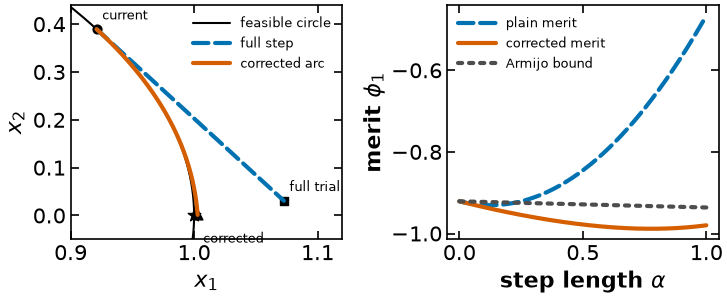

In [23]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.3))
t_circle = np.linspace(-.05, .48, 201)
axes[0].plot(np.cos(t_circle),np.sin(t_circle),"k-",lw=1.5,label="feasible circle")
for key,label,color,ls in [("plain_arc","full step","#0072B2","--"),("corrected_arc","corrected arc","#D55E00","-")]:
    arc=np.asarray(results[key])
    axes[0].plot(arc[:,0],arc[:,1],color=color,ls=ls,label=label)
for key,marker,label in [("point","o","current"),("trial","s","full trial"),("corrected","^","corrected")]:
    point_here=np.asarray(results[key]);axes[0].scatter(*point_here,marker=marker,s=40,color="black")
    axes[0].annotate(label,point_here,xytext=(4,7 if key!="corrected" else -20),textcoords="offset points",fontsize=9)
axes[0].scatter(1,0,marker="*",s=90,color="black")
axes[0].set(xlabel="$x_1$",ylabel="$x_2$",xlim=(.9,1.12),ylim=(-.05,.44))
axes[0].legend(loc="upper right",fontsize=9)
for key,label,color,ls in [("plain_merit","plain merit","#0072B2","--"),("corrected_merit","corrected merit","#D55E00","-"),("armijo","Armijo bound","0.3",":")]:
    axes[1].plot(results["alpha"],results[key],label=label,color=color,ls=ls)
axes[1].set(xlabel=r"step length $\alpha$",ylabel=r"merit $\phi_1$")
axes[1].legend(loc="upper left",fontsize=9)
fig.tight_layout()
helper.save_figure(fig,"cg-maratos",quiet=True)

### With and without the correction

Compare the reported step lengths and residuals for the starts below. Full-step acceptance is a local, safeguarded property; a correction's mere merit decrease does not establish Armijo acceptance at arbitrary starts.


In [24]:
print(f"{'vartheta':>10s} {'SOC':>6s} {'iters':>7s}  step lengths (first five)")
for vartheta in [0.1, 0.2, 0.4]:
    x0 = np.array([np.cos(vartheta), np.sin(vartheta)])
    for use_soc in [False, True]:
        res = sqp(**prob_m, x0=x0, hessian="exact", soc=use_soc, max_iter=60)
        assert res["status"] == "converged", res["status"]
        assert linalg.norm(res["x"] - x_star_m) < 1e-6
        print(
            f"{vartheta:10.2f} {str(use_soc):>6s} {res['n_iter']:7d}  "
            f"{np.round(res['hist']['alpha'][:5], 4)}"
        )

ref = minimize(
    f_m,
    [np.cos(0.4), np.sin(0.4)],
    jac=grad_m,
    method="SLSQP",
    constraints=[{"type": "eq", "fun": h_m, "jac": jac_m}],
    options={"ftol": 1e-14},
)
assert ref.success, f"SLSQP failed: {ref.message}"
print(f"\nSLSQP reference: x = {ref.x}, f = {ref.fun:.12f}")
print(f"analytic       : x* = {x_star_m}, f* = -1.0, lambda* = -1.5")

  vartheta    SOC   iters  step lengths (first five)
      0.10  False       8  [1.   0.25 0.25 0.5  1.  ]
      0.10   True       5  [1. 1. 1. 1.]
      0.20  False       8  [1.   0.25 0.25 0.5  1.  ]
      0.20   True       5  [1. 1. 1. 1.]
      0.40  False       8  [1.   0.25 0.25 0.5  1.  ]
      0.40   True       6  [1. 1. 1. 1. 1.]

SLSQP reference: x = [1.00000000e+00 3.86543361e-12], f = -1.000000000000
analytic       : x* = [1. 0.], f* = -1.0, lambda* = -1.5


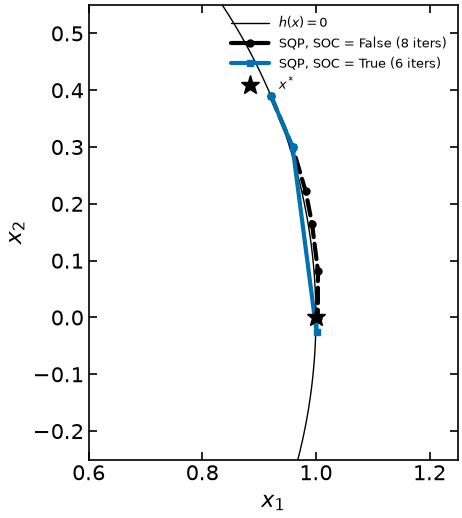

In [25]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))

# The feasible set: the unit circle.
t = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(t), np.sin(t), "k-", lw=1, label="$h(x) = 0$")

for use_soc, style, marker in [(False, "--", "o"), (True, "-", "s")]:
    res = sqp(
        **prob_m,
        x0=np.array([np.cos(0.4), np.sin(0.4)]),
        hessian="exact",
        soc=use_soc,
        max_iter=60,
    )
    path = np.array(res["hist"]["x"])
    ax.plot(
        path[:, 0],
        path[:, 1],
        style,
        marker=marker,
        ms=5,
        label=f"SQP, SOC = {use_soc} ({res['n_iter']} iters)",
    )

ax.plot(1.0, 0.0, "k*", ms=14, label="$x^*$")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_xlim(0.6, 1.25)
ax.set_ylim(-0.25, 0.55)
ax.set_aspect("equal")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

## Shared Lecture 23 computations

These figures use the actual solver functions above. The first separates the smallest **feasible** relaxation from the chosen weighted optimum; the second applies damping to a constrained step with positive tangent curvature. The final table checks original-point residuals, including preserved failure runs.

In [26]:
# Actual Example 6.3 QP: solve once, archive data for website and handout.
import helper
helper.set_plotting_style()
point_elastic = np.array([0., .1, 0., 0.])
d_elastic, xi_elastic, v_elastic, zeta_elastic, nit_elastic = solve_sqp_subproblem(
    grad3(point_elastic), np.eye(4), h3(point_elastic), jac3(point_elastic),
    x3_lo-point_elastic, x3_hi-point_elastic, M=1e4)
xi_min_elastic = 1-.76/1.98
assert xi_elastic >= xi_min_elastic-1e-8
np.testing.assert_allclose((1-xi_elastic)*h3(point_elastic)+jac3(point_elastic)@d_elastic, 0, atol=1e-9)
elastic_data = {"point":point_elastic.tolist(), "minimum_feasible_xi":float(xi_min_elastic),
    "xi":float(xi_elastic), "step":d_elastic.tolist(), "eq_multipliers":v_elastic.tolist(),
    "signed_bound_gradient":zeta_elastic.tolist(), "inner_passes":int(nit_elastic),
    "residual_sum":float(sum(h3(point_elastic))), "d2_coefficient":.4,
    "d2_upper":float(x3_hi[1]-point_elastic[1]), "xi_grid":np.linspace(0,1,201).tolist()}
helper.save_results("sqp-elastic-actual",elastic_data,notebook="notebooks/7-dev/SQP.ipynb",
    source_cells=[("notebooks/7-dev/SQP.ipynb",t) for t in ["results:sqp-bound-solver","results:sqp-elastic-solver","results:sqp-biegler-model","results:sqp-elastic-actual"]],
    description="Actual scalar elastic QP on corrected Biegler Example 6.3; feasible threshold and chosen weighted step.",solver="dense active-set scipy KKT solves",quiet=True)
results = elastic_data
print("minimum feasible xi:",results["minimum_feasible_xi"],"selected xi:",results["xi"])
print("selected step:",results["step"],"QP equality multipliers:",results["eq_multipliers"])


minimum feasible xi: 0.6161616161616161 selected xi: 0.6161616161616161
selected step: [0.0, 1.9, 0.0, 0.0] QP equality multipliers: [8161.932404856648, 8162.932404856648]


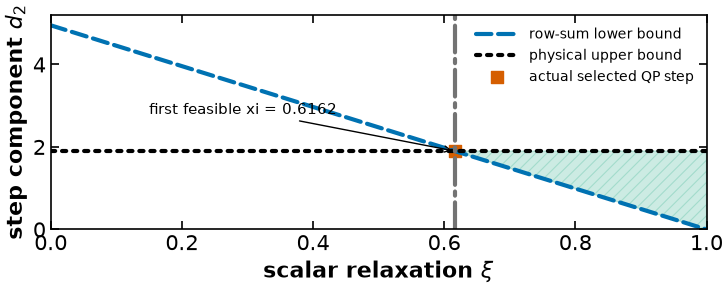

In [27]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7.6,3.1))
xigrid=np.asarray(results["xi_grid"])
lower=results["residual_sum"]*(1-xigrid)/results["d2_coefficient"]
ax.plot(xigrid,lower,"--",color="#0072B2",label="row-sum lower bound")
ax.axhline(results["d2_upper"],color="black",ls=":",label="physical upper bound")
ax.fill_between(xigrid,lower,results["d2_upper"],where=lower<=results["d2_upper"],color="#009E73",alpha=.2,hatch="///")
ax.scatter(results["xi"],results["step"][1],color="#D55E00",marker="s",s=65,label="actual selected QP step")
ax.axvline(results["minimum_feasible_xi"],color="0.45",ls="-.")
ax.annotate(f"first feasible xi = {results['minimum_feasible_xi']:.4f}",(results["minimum_feasible_xi"],1.9),xytext=(.15,2.8),arrowprops={"arrowstyle":"->"},fontsize=11)
ax.set(xlabel=r"scalar relaxation $\xi$",ylabel=r"step component $d_2$",xlim=(0,1),ylim=(0,5.2))
ax.legend(loc="upper right",fontsize=10)
fig.tight_layout()
helper.save_figure(fig,"sqp-elastic-actual",quiet=True)


### Damping at a constrained minimum

Use $f=-2x_1^2+\frac12(x_2-2)^2$, $h=x_1$, current $(-1,-1)$ and $\mathbf B=\operatorname{diag}(2,3)$. The exact full Hessian is indefinite, but the tangent direction $(0,1)$ has curvature 1. `solve_kkt` computes the step; `damped_bfgs_update` supplies the update. Scaling the same construction toward $(0,2)$ keeps $\mathbf s^{\mathsf T}\mathbf y<0$.

In [28]:
point_damping = np.array([-1.,-1.])
B_damping = np.diag([2.,3.])
W_damping = np.diag([-4.,1.])
g_damping = np.array([-4*point_damping[0],point_damping[1]-2])
J_damping = np.array([[1.,0.]])
s_damping, v_damping = solve_kkt(B_damping,g_damping,J_damping,np.array([point_damping[0]]))
y_damping = W_damping@s_damping
new_B_damping, theta_damping = damped_bfgs_update(B_damping,s_damping,y_damping)
r_damping = theta_damping*y_damping+(1-theta_damping)*B_damping@s_damping
np.testing.assert_allclose(s_damping,[1,1])
assert s_damping@y_damping < 0 and np.linalg.eigvalsh(new_B_damping).min()>0
np.testing.assert_allclose(s_damping@r_damping,.2*(s_damping@B_damping@s_damping))
damping_data = {"point":point_damping.tolist(),"B":B_damping.tolist(),"W":W_damping.tolist(),
    "step":s_damping.tolist(),"eq_multiplier":v_damping.tolist(),"y":y_damping.tolist(),
    "Bs":(B_damping@s_damping).tolist(),"r":r_damping.tolist(),"theta":float(theta_damping),
    "sBs":float(s_damping@B_damping@s_damping),"sy":float(s_damping@y_damping),
    "sr":float(s_damping@r_damping),"new_B":new_B_damping.tolist(),
    "new_eigenvalues":np.linalg.eigvalsh(new_B_damping).tolist()}
helper.save_results("sqp-constrained-damping",damping_data,notebook="notebooks/7-dev/SQP.ipynb",
    source_cells=[("notebooks/7-dev/SQP.ipynb",t) for t in ["results:maratos-kkt-solver","results:sqp-damping-solver","results:sqp-constrained-damping"]],
    description="Actual constrained QP step and fixed-multiplier secant; existing Powell damping function.",solver="scipy.linalg.solve and original damped_bfgs_update",quiet=True)
results = damping_data
print("s, y, Bs, r:",*[results[key] for key in ["step","y","Bs","r"]])
print("sBs, sy, sr, theta:",*[results[key] for key in ["sBs","sy","sr","theta"]])
print("new B:",results["new_B"],"eigenvalues:",results["new_eigenvalues"])


s, y, Bs, r: [1.0, 1.0] [-4.0, 1.0] [2.0, 3.0] [-1.0, 2.0]
sBs, sy, sr, theta: 5.0 -3.0 1.0 0.5
new B: [[2.2, -3.2], [-3.2, 5.2]] eigenvalues: [0.16588059058554183, 7.2341194094144585]


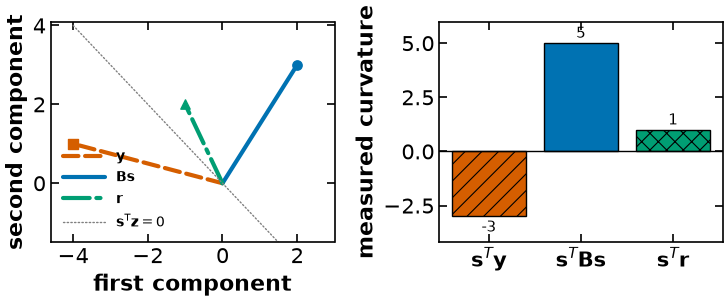

In [29]:
import matplotlib.pyplot as plt
fig, axes=plt.subplots(1,2,figsize=(7.6,3.2))
for key,label,color,ls in [("y",r"$\mathbf{y}$","#D55E00","--"),("Bs",r"$\mathbf{B}\mathbf{s}$","#0072B2","-"),("r",r"$\mathbf{r}$","#009E73","-.")]:
    vec=np.asarray(results[key]);axes[0].plot([0,vec[0]],[0,vec[1]],color=color,ls=ls,label=label)
    axes[0].scatter(*vec,color=color,marker={"y":"s","Bs":"o","r":"^"}[key],s=45)
axes[0].plot([-4,3],[4,-3],color="0.5",ls=":",lw=1,label=r"$\mathbf{s}^{\mathsf{T}}\mathbf{z}=0$")
axes[0].set(xlabel="first component",ylabel="second component",xlim=(-4.6,3),ylim=(-1.5,4.1))
axes[0].legend(loc="lower left",fontsize=10)
labels=[r"$\mathbf{s}^T\mathbf{y}$",r"$\mathbf{s}^T\mathbf{B}\mathbf{s}$",r"$\mathbf{s}^T\mathbf{r}$"]
for i,(v,col,hatch) in enumerate(zip([results["sy"],results["sBs"],results["sr"]],["#D55E00","#0072B2","#009E73"],["//","","xx"])):
    axes[1].bar(i,v,color=col,hatch=hatch,edgecolor="black")
    axes[1].text(i,v+(.25 if v>=0 else -.7),f"{v:g}",ha="center",fontsize=11)
axes[1].axhline(0,color="black",lw=1)
axes[1].set(xticks=range(3),xticklabels=labels,ylabel="measured curvature",ylim=(-4.2,6))
fig.tight_layout()
helper.save_figure(fig,"sqp-constrained-damping",quiet=True)


### Original-point diagnostics across both Hessian modes

All runs below use `eps_d=eps_h=1e-12` and `max_iter=100`. Equality multipliers come from the original result. The prototype does **not** return bound multipliers: the table reconstructs nonnegative values from the final gradient on bounds active within `1e-7`, then checks stationarity and complementarity. This is a diagnostic reconstruction, not an inner-solver certificate. Missing bounds use zero multipliers. The plotting floor `1e-16` only makes zero residuals visible on the log scale.

In [30]:
import contextlib, io
rows_diagnostics=[]
for name,prob,starts,lo,hi in [("circle",prob1,[[-2,-1]],None,None),
    ("bound",prob2,[[1.4,.2]],x2_lo,x2_hi),
    ("Biegler .1",prob3,[[0,.1,0,0]],x3_lo,x3_hi),
    ("Biegler zero",prob3,[[0,0,0,0]],x3_lo,x3_hi)]:
    for start in starts:
        for mode in ["bfgs","exact"]:
            with contextlib.redirect_stdout(io.StringIO()):
                run=sqp(**prob,x0=start,x_lo=lo,x_hi=hi,hessian=mode,eps_d=1e-12,eps_h=1e-12,max_iter=100)
            x_final=run["x"];v_final=run["lam"]
            z_final=prob["calc_grad"](x_final)+prob["calc_jac"](x_final).T@v_final
            if lo is None:
                u_lower=u_upper=np.zeros(len(x_final));bound_violation=comp=0.
            else:
                at_lower=abs(x_final-lo)<1e-7;at_upper=abs(x_final-hi)<1e-7
                u_lower=np.where(at_lower,np.maximum(z_final,0),0)
                u_upper=np.where(at_upper,np.maximum(-z_final,0),0)
                bound_violation=float(max(np.max(np.maximum(lo-x_final,0)),np.max(np.maximum(x_final-hi,0))))
                comp=float(max(np.max(abs(u_lower*(x_final-lo))),np.max(abs(u_upper*(hi-x_final)))))
            row={"example":name,"mode":mode,"status":run["status"],"iterations":int(run["n_iter"]),
                "x":x_final.tolist(),"returned_eq_multipliers":v_final.tolist(),
                "inferred_lower":u_lower.tolist(),"inferred_upper":u_upper.tolist(),
                "f":float(run["f"]),"feasibility":float(np.linalg.norm(run["h"],np.inf)),
                "stationarity":float(np.linalg.norm(z_final-u_lower+u_upper,np.inf)),
                "bound_violation":bound_violation,"complementarity":comp}
            rows_diagnostics.append(row)
diagnostics_data={"rows":rows_diagnostics,"plot_floor":1e-16,"bound_multiplier_scope":"Reconstructed on tolerance-active final bounds, not returned by the prototype."}
helper.save_results("sqp-original-residuals",diagnostics_data,notebook="notebooks/7-dev/SQP.ipynb",
    source_cells=[("notebooks/7-dev/SQP.ipynb",t) for t in ["results:maratos-kkt-solver","results:sqp-bound-solver","results:sqp-elastic-solver","results:sqp-damping-solver","results:sqp-convexification","results:sqp-outer-solver","results:sqp-circle-model","results:sqp-bound-model","results:sqp-biegler-model","results:sqp-original-residuals"]],
    description="Actual original SQP runs and final original-point KKT diagnostics; reconstructed bound multipliers explicitly distinguished.",solver="original dense SQP prototype",quiet=True)
results=diagnostics_data
print(f"{'example':14} {'mode':6} {'status':14} {'iter':4} {'f':>10} {'||h||inf':>12} {'stationarity':>12} {'comp':>10}")
for row in rows_diagnostics:
    print(f"{row['example']:14} {row['mode']:6} {row['status']:14} {row['iterations']:4} {row['f']:10.5f} {row['feasibility']:12.4e} {row['stationarity']:12.4e} {row['complementarity']:10.3e}")


example        mode   status         iter          f     ||h||inf stationarity       comp
circle         bfgs   converged         7   -2.00000   0.0000e+00   4.4409e-16  0.000e+00
circle         exact  converged         8   -2.00000   4.4409e-16   2.3326e-13  0.000e+00
bound          bfgs   converged         6    2.13524   4.4409e-16   8.8818e-16  0.000e+00
bound          exact  converged         6    2.13524   4.4409e-16   6.6613e-16  0.000e+00
Biegler .1     bfgs   converged         8   -1.00000   0.0000e+00   0.0000e+00  0.000e+00
Biegler .1     exact  maximum iterations  100    0.90270   2.5148e-05   2.1557e-01  0.000e+00
Biegler zero   bfgs   inconsistent linearization (xi = 1)    1    0.00000   1.0000e+00   1.0000e+00  0.000e+00
Biegler zero   exact  inconsistent linearization (xi = 1)    1    0.00000   1.0000e+00   1.0000e+00  0.000e+00


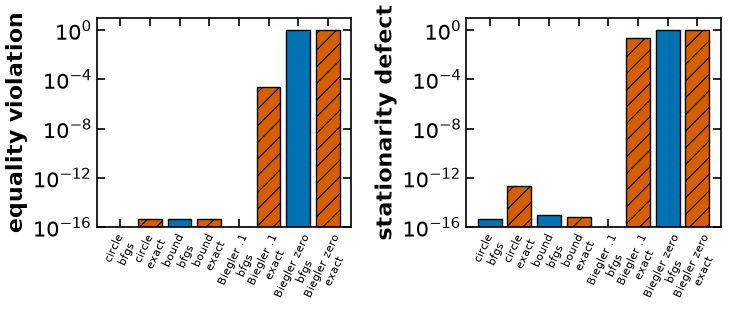

In [31]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(7.6,3.3))
labels=[r["example"]+"\n"+r["mode"] for r in results["rows"]]
for ax,key,title in zip(axes,["feasibility","stationarity"],["equality violation","stationarity defect"]):
    vals=[max(r[key],results["plot_floor"]) for r in results["rows"]]
    for i,v in enumerate(vals):
        ax.bar(i,v,color="#0072B2" if i%2==0 else "#D55E00",hatch="" if i%2==0 else "//",edgecolor="black")
    ax.set_yscale("log");ax.set(xticks=range(len(labels)),xticklabels=labels,ylabel=title,ylim=(1e-16,10))
    ax.tick_params(axis="x",labelsize=8,labelrotation=65)
fig.tight_layout()
helper.save_figure(fig,"sqp-original-residuals",quiet=True)


## Algorithms beyond the prototype

The native guide above includes the [trust-region families](#sqp-trust-models), [SLQP](#sqp-iqp-eqp-slqp), [reduced-space bounds](#sqp-reduced-bounds), and [sparse factorization updates](#sqp-sparse-updates). The code uses dense systems and bound-form inequalities, with no outer working-set warm start or feasibility restoration implementation. The complete [globalization reference](Constrained-Globalization.ipynb) describes restoration and filter safeguards. Reaching a useful nonlinear point from a poor start remains an algorithmic task; these omissions are not guarantees of failure or success.